

# <center> **Segmentación y clasificación de tumores cerebrales en MRI** </center>
### <center> YOLO26-seg + recorte de parche + U-Net </center>

**Integrantes:** Uber Armando Capacho Jaimes · Wilmer Alejandro Sarmiento Gafaro

**Materia:** Inteligencia Artificial II (Deep Learning) – UIS

## 1. Introducción y objetivo

Delimitar un tumor cerebral a mano en una resonancia magnética (MRI) es lento, puede retrasar cirugías y tratamientos, y depende del criterio de cada especialista. Una herramienta de Deep Learning puede agilizar el proceso.

**Objetivo:** detectar, clasificar (glioma, meningioma, pituitario o sin tumor) y segmentar tumores cerebrales en imágenes MRI usando un pipeline de dos etapas:

1. **YOLO26-seg:** localiza el tumor, lo clasifica y entrega una máscara gruesa.
2. **Recorte del parche** alrededor de la caja detectada.
3. **U-Net:** segmenta el parche con más detalle y la máscara se pega de nuevo en la imagen original.

**Dataset:** *Brain Tumor Dataset: Segmentation & Classification* (Kaggle, público). Aprox. 6.000 cortes MRI con máscaras.

In [ ]:
#@title 2. Instalar librerías (solo la primera vez) { display-mode: "form" }
!pip -q install ultralytics kagglehub

In [ ]:
#@title 3. CARPETA DE TRABAJO (sin Drive) { display-mode: "form" }
import os, shutil
from google.colab import files
RESULTS_DIR = '/content/IA2_proyecto'
os.makedirs(RESULTS_DIR, exist_ok=True)

def guardar_respaldo(nombre="respaldo_IA2"):
    if os.path.isdir("/content/runs/yolo_seg"):
        shutil.copytree("/content/runs/yolo_seg", f"{RESULTS_DIR}/yolo_seg", dirs_exist_ok=True)
    shutil.make_archive(f"/content/{nombre}", "zip", RESULTS_DIR)
    files.download(f"/content/{nombre}.zip")

In [ ]:
#@title Cargar librerías (usa GPU si hay, si no CPU) { display-mode: "form" }
import os, re, random, shutil
from pathlib import Path
from collections import Counter

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from matplotlib.patches import FancyBboxPatch

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

import torch
import kagglehub
from ultralytics import YOLO

# OJO: TensorFlow se importa más adelante (sección 8) para que no compita con YOLO por la GPU
DEVICE = 0 if torch.cuda.is_available() else "cpu"
if DEVICE == "cpu":
    torch.set_num_threads(os.cpu_count())
print("Dispositivo YOLO:", DEVICE)
print("GPU disponible:", torch.cuda.is_available(), "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "SIN GPU")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Dispositivo YOLO: 0
GPU disponible: True | Tesla T4


## 4. Configuración experimental: hiperparámetros y decisiones

Todas las decisiones importantes están en una sola celda para poder cambiarlas y para mostrarlas en la presentación.

> **Modo CPU / rápido:** los valores por defecto (15 épocas de YOLO, imágenes de 320 px, 300 imágenes de train por clase) están pensados para correr sin GPU. Si tienes GPU y quieres el entrenamiento completo, sube `YOLO_EPOCHS`, `YOLO_IMGSZ` y pon `MAX_TRAIN_CLASE = 0`.


In [ ]:
#@title Hiperparámetros { display-mode: "form" }
SEED = 42 #@param {type:"integer"}

# --- MODO RÁPIDO (CPU): usa solo parte del dataset. Pon 0 para usar todo ---
MAX_TRAIN_CLASE = 300 #@param {type:"integer"}   # imágenes de train por clase (0 = todas)
MAX_VAL_TEST_CLASE = 80 #@param {type:"integer"} # imágenes de val y de test por clase (0 = todas)

# --- Etapa 1: YOLO con cabeza de segmentación ---
YOLO_MODEL  = "yolo26n-seg.pt" #@param ["yolo26n-seg.pt", "yolo26s-seg.pt", "yolo11n-seg.pt"]
YOLO_EPOCHS = 15 #@param {type:"integer"}
YOLO_IMGSZ  = 320 #@param {type:"integer"}
YOLO_BATCH  = 16 #@param {type:"integer"}
YOLO_CONF   = 0.25 #@param {type:"number"}      # confianza mínima para DECIDIR LA CLASE (tumor / sin tumor)
YOLO_CONF_CROP = 0.01 #@param {type:"number"}   # NUEVO: confianza mínima para quedarse con la CAJA que se recorta (casi cualquiera sirve)

# --- Etapa 2: U-Net sobre el parche recortado ---
PATCH       = 128 #@param {type:"integer"}
MARGIN      = 0.2 #@param {type:"number"}
FEAT_SIZE   = 32 #@param {type:"integer"}        # NUEVO: tamaño (alto = ancho) del recorte de features de YOLO
UNET_EPOCHS = 30 #@param {type:"integer"}
UNET_BATCH  = 16 #@param {type:"integer"}
UNET_LR     = 1e-3 #@param {type:"number"}
UNET_FILTERS = 16 #@param {type:"integer"}
UNET_DROPOUT = 0.1 #@param {type:"number"}

random.seed(SEED); np.random.seed(SEED)
NAMES = ["glioma", "meningioma", "pituitary", "sin_tumor"]   # 0,1,2 = tumores; 3 = sin tumor

hp = pd.DataFrame({
    "Etapa": ["YOLO"]*6 + ["U-Net"]*8,
    "Hiperparámetro": ["modelo", "épocas", "tamaño de imagen", "batch", "confianza mínima (clase)", "confianza mínima (caja a recortar)",
                       "tamaño del parche", "margen del recorte", "tamaño del recorte de features", "épocas máx. (early stopping)",
                       "batch", "learning rate", "filtros base", "dropout"],
    "Valor": [YOLO_MODEL, YOLO_EPOCHS, YOLO_IMGSZ, YOLO_BATCH, YOLO_CONF, YOLO_CONF_CROP,
              PATCH, MARGIN, FEAT_SIZE, UNET_EPOCHS, UNET_BATCH, UNET_LR, UNET_FILTERS, UNET_DROPOUT]})
hp

,Etapa,Hiperparámetro,Valor
0,YOLO,modelo,yolo26n-seg.pt
1,YOLO,épocas,15
2,YOLO,tamaño de imagen,320
3,YOLO,batch,16
4,YOLO,confianza mínima (clase),0.25
5,YOLO,confianza mínima (caja a recortar),0.01
6,U-Net,tamaño del parche,128
7,U-Net,margen del recorte,0.2
8,U-Net,tamaño del recorte de features,32
9,U-Net,épocas máx. (early stopping),30


### ¿Por qué estas métricas?

| Tarea | Métrica | Por qué |
|---|---|---|
| Segmentación | **Dice** e **IoU** | Miden cuánto se solapa la máscara predicha con la real. El tumor ocupa pocos píxeles frente al fondo, así que la *accuracy* por píxel sería engañosa (predecir todo "fondo" ya daría un valor alto). |
| Clasificación | **Accuracy, precision, recall y F1** + matriz de confusión | Muestran qué clases se confunden. El **recall** importa mucho: no detectar un tumor es el error más costoso. |
| Detección | **mAP50** | Métrica estándar de YOLO: evalúa caja y clase a la vez. |

## 5. Dataset

Descargamos el dataset público desde Kaggle y revisamos cómo vienen las carpetas.

In [ ]:
#@title Descargar el dataset de Kaggle { display-mode: "form" }
path = kagglehub.dataset_download("indk214/brain-tumor-dataset-segmentation-and-classification")
ROOT = Path(path)
print("Dataset en:", ROOT)

100%|██████████| 723M/723M [00:18<00:00, 41.9MB/s]

Extracting files...


Dataset en: /root/.cache/kagglehub/datasets/indk214/brain-tumor-dataset-segmentation-and-classification/versions/1


In [ ]:
#@title Explorar la estructura de carpetas { display-mode: "form" }
EXT = {".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp"}
files = [p for p in ROOT.rglob("*") if p.suffix.lower() in EXT]
print("Total de imágenes encontradas:", len(files))
cnt = Counter(str(p.parent.relative_to(ROOT)) for p in files)
for k, v in sorted(cnt.items()):
    print(f"{v:6d}  {k}")
print("\nEjemplos de nombres:")
for p in files[:5]:
    print(" ", p.relative_to(ROOT))
print("Resolución de una imagen (alto, ancho):", cv2.imread(str(files[0])).shape[:2])

Total de imágenes encontradas: 11407
  1108  DATASET/Segmentation/Glioma
  1416  DATASET/Segmentation/Meningioma
  1860  DATASET/Segmentation/Pituitary tumor
   300  DATASET/classification/Testing/glioma
   306  DATASET/classification/Testing/meningioma
   405  DATASET/classification/Testing/notumor
   300  DATASET/classification/Testing/pituitary
  1321  DATASET/classification/Training/glioma
  1339  DATASET/classification/Training/meningioma
  1595  DATASET/classification/Training/notumor
  1457  DATASET/classification/Training/pituitary

Ejemplos de nombres:
  DATASET/Segmentation/Meningioma/enh_397.png
  DATASET/Segmentation/Meningioma/enh_546_mask.png
  DATASET/Segmentation/Meningioma/enh_593.png
  DATASET/Segmentation/Meningioma/enh_521_mask.png
  DATASET/Segmentation/Meningioma/enh_160.png
Resolución de una imagen (alto, ancho): (512, 512)


### Emparejar cada imagen con su máscara y asignar la clase
No conocemos de antemano la estructura exacta, así que el código separa imágenes y máscaras por el nombre ("mask") y deduce la clase por carpeta o por el nombre del archivo.

In [ ]:
#@title **code** Funciones para emparejar imágenes, máscaras y clases { display-mode: "form" }
def is_mask(p):
    return "mask" in str(p.relative_to(ROOT)).lower()

def norm_stem(p):
    """Nombre sin la palabra 'mask', para emparejar imagen <-> máscara."""
    return re.sub(r"[_\-]?masks?", "", p.stem.lower())

def get_cls(p):
    """Clase a partir de la carpeta o del nombre del archivo. Devuelve None si no la encuentra."""
    s = str(p.relative_to(ROOT)).lower()
    if "glioma" in s: return 0
    if "meningioma" in s: return 1
    if "pituitary" in s: return 2
    if re.search(r"no[_\- ]?tumou?r|notumou?r|healthy|normal", s): return 3
    toks = re.split(r"[_\-. /\\]", s)
    for t, c in (("gl", 0), ("me", 1), ("pi", 2), ("no", 3)):
        if t in toks: return c
    return None

def read_mask(item, shape):
    """Lee la máscara binaria (0/1) y la ajusta al tamaño de la imagen. Sin máscara = todo fondo."""
    if item["mask"] is None: return np.zeros(shape, np.uint8)
    m = cv2.imread(str(item["mask"]), cv2.IMREAD_GRAYSCALE)
    if m.shape != shape: m = cv2.resize(m, (shape[1], shape[0]), interpolation=cv2.INTER_NEAREST)
    return (m > 127).astype(np.uint8)

In [ ]:
#@title Construir la lista de muestras { display-mode: "form" }
imgs, masks = {}, {}
for p in files:
    k = norm_stem(p)
    d = masks if is_mask(p) else imgs
    if k not in d or "segmentation" in str(p).lower(): d[k] = p

items, skipped = [], 0
for k, p in imgs.items():
    m = masks.get(k)
    c = get_cls(p)
    if c is None and m is not None: c = get_cls(m)
    if c is None or (m is None and c != 3):
        skipped += 1; continue
    toks = set(re.split(r"[_\-. /\\]", str(p.relative_to(ROOT)).lower()))
    split = "test" if "test" in toks else ("train" if "train" in toks else None)
    items.append(dict(img=p, mask=m, cls=c, split=split))

print("Pares válidos:", len(items), "| descartados:", skipped)
assert len(items) > 0, "No se encontraron pares. Revisa la salida de la celda de exploración."

Pares válidos: 4192 | descartados: 5023


Muestras totales: 4192 -> modo rápido: 1840


split,test,train,val,All
clase,,,,
glioma,80,300,80,460
meningioma,80,300,80,460
pituitary,80,300,80,460
sin_tumor,80,300,80,460
All,320,1200,320,1840


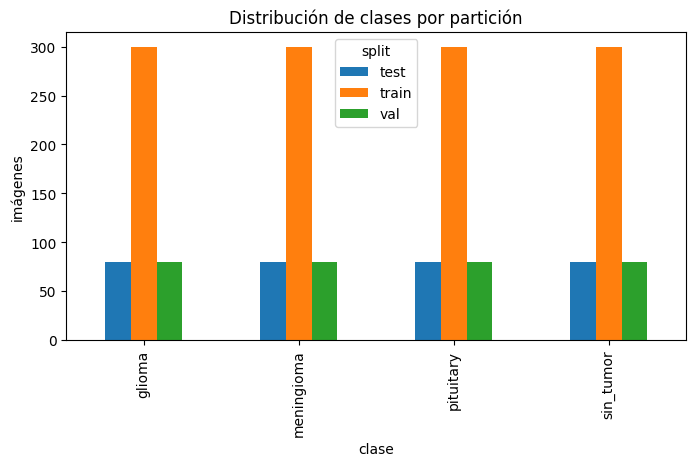

In [ ]:
#@title Partición train / val / test { display-mode: "form" }
# Si el dataset ya trae train/test se respeta; si no, 70/15/15 estratificado por clase
rng = random.Random(SEED)
has_test = any(i["split"] == "test" for i in items)
for c in range(4):
    grp = [i for i in items if i["cls"] == c]
    rng.shuffle(grp)
    if has_test:
        pool = [i for i in grp if i["split"] != "test"]
        nval = int(0.15 * len(pool))
        for j, i in enumerate(pool): i["split"] = "val" if j < nval else "train"
    else:
        n = len(grp); a, b = int(0.7 * n), int(0.85 * n)
        for j, i in enumerate(grp): i["split"] = "train" if j < a else ("val" if j < b else "test")

# MODO RÁPIDO: recorta cada partición a un máximo por clase (acelera YOLO y U-Net en CPU)
if MAX_TRAIN_CLASE or MAX_VAL_TEST_CLASE:
    keep, vistos = [], Counter()
    for i in items:
        lim = MAX_TRAIN_CLASE if i["split"] == "train" else MAX_VAL_TEST_CLASE
        k = (i["cls"], i["split"])
        if lim == 0 or vistos[k] < lim:
            vistos[k] += 1; keep.append(i)
    print("Muestras totales:", len(items), "-> modo rápido:", len(keep))
    items = keep

tabla = pd.DataFrame([{"clase": NAMES[i["cls"]], "split": i["split"]} for i in items])
dist = pd.crosstab(tabla["clase"], tabla["split"], margins=True)
display(dist)
dist.drop("All").drop(columns="All").plot(kind="bar", figsize=(8, 4), title="Distribución de clases por partición")
plt.ylabel("imágenes"); plt.show()

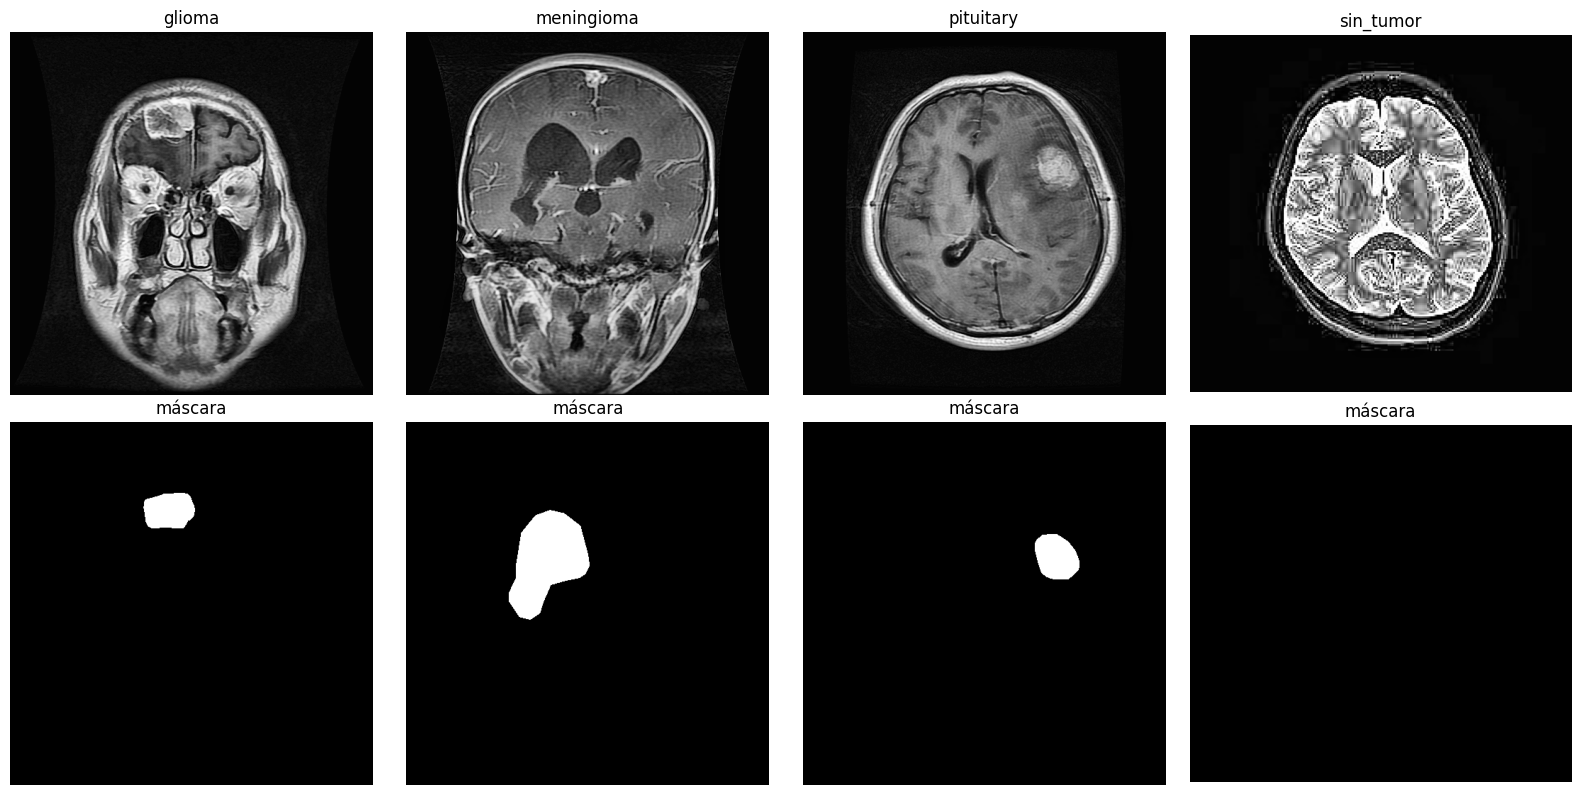

In [ ]:
#@title **Observa una muestra por clase** { display-mode: "form" }
plt.figure(figsize=(16, 8))
for c in range(4):
    it = next(i for i in items if i["cls"] == c)
    im = cv2.imread(str(it["img"])); gt = read_mask(it, im.shape[:2])
    plt.subplot(2, 4, c + 1); plt.imshow(im[..., ::-1]); plt.title(NAMES[c]); plt.axis("off")
    plt.subplot(2, 4, c + 5); plt.imshow(gt, cmap="gray"); plt.title("máscara"); plt.axis("off")
plt.tight_layout(); plt.show()

## 6. Método propuesto

### Pipeline

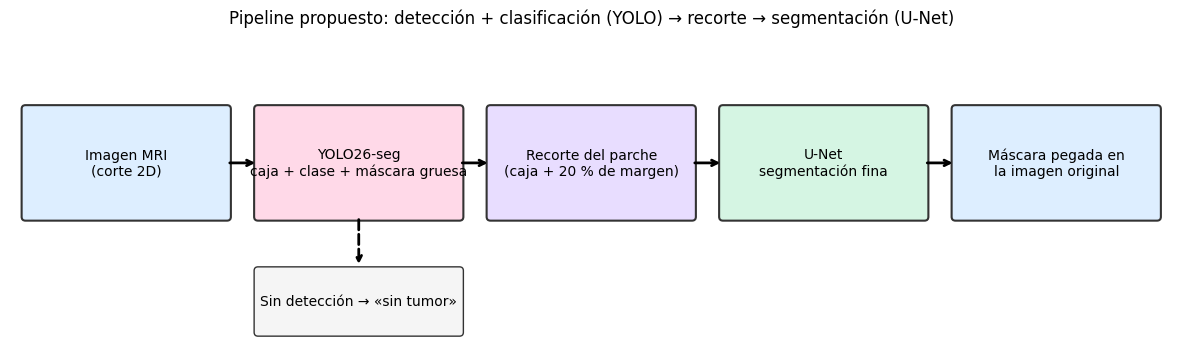

In [ ]:
#@title Diagrama del pipeline (úsalo en la presentación) { display-mode: "form" }
fig, ax = plt.subplots(figsize=(15, 4))
ax.set_xlim(0, 15); ax.set_ylim(0, 4); ax.axis("off")
cajas = [(0.2,  "Imagen MRI\n(corte 2D)",                      "#DDEEFF"),
         (3.2,  "YOLO26-seg\ncaja + clase + máscara gruesa",   "#FFD9E8"),
         (6.2,  "Recorte del parche\n(caja + 20 % de margen)", "#E8DDFF"),
         (9.2,  "U-Net\nsegmentación fina",                    "#D5F5E3"),
         (12.2, "Máscara pegada en\nla imagen original",       "#DDEEFF")]
w, h, y = 2.6, 1.4, 1.6
for x, txt, col in cajas:
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05", fc=col, ec="#333", lw=1.5))
    ax.text(x + w / 2, y + h / 2, txt, ha="center", va="center", fontsize=10)
for i in range(len(cajas) - 1):
    ax.annotate("", xy=(cajas[i + 1][0], y + h / 2), xytext=(cajas[i][0] + w, y + h / 2),
                arrowprops=dict(arrowstyle="->", lw=2))
ax.add_patch(FancyBboxPatch((3.2, 0.1), w, 0.8, boxstyle="round,pad=0.05", fc="#F5F5F5", ec="#333"))
ax.text(3.2 + w / 2, 0.5, "Sin detección → «sin tumor»", ha="center", va="center", fontsize=10)
ax.annotate("", xy=(3.2 + w / 2, 0.95), xytext=(3.2 + w / 2, y), arrowprops=dict(arrowstyle="->", lw=2, ls="--"))
ax.set_title("Pipeline propuesto: detección + clasificación (YOLO) → recorte → segmentación (U-Net)")
plt.savefig(f"{RESULTS_DIR}/pipeline.png", dpi=200, bbox_inches="tight"); plt.show()

### ¿Por qué estos modelos?

- **YOLO26-seg (versión más reciente de YOLO, con cabeza de segmentación):** es rápido, localiza el tumor y lo clasifica en un solo paso, y su cabeza de segmentación da una máscara inicial. Además resuelve el caso "sin tumor": si no detecta nada, no hay tumor.
- **Recorte del parche:** el tumor ocupa una zona pequeña de la imagen. Al recortar, la U-Net trabaja solo sobre la región de interés y el problema de desbalance entre fondo y tumor se reduce.
- **U-Net (Ronneberger et al., 2015):** es la arquitectura estándar en segmentación médica. Las conexiones *skip* conservan el detalle espacial, lo que da bordes más precisos que la máscara de YOLO. Es el paper base del proyecto.

## 7. Etapa 1: YOLO26-seg

### Convertir las máscaras a formato YOLO
YOLO-seg necesita los contornos del tumor como polígonos normalizados. Las imágenes **sin tumor** quedan con archivo de etiqueta vacío (fondo).

In [ ]:
#@title **code** Convertir máscaras a polígonos y crear el dataset YOLO { display-mode: "form" }
YDIR = Path("/content/yolo_data")
if YDIR.exists(): shutil.rmtree(YDIR)

def mask_to_polys(m):
    """Máscara binaria -> lista de polígonos normalizados [0,1]."""
    h, w = m.shape
    cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    out = []
    for c in cnts:
        if cv2.contourArea(c) < 30: continue
        c = cv2.approxPolyDP(c, 0.002 * cv2.arcLength(c, True), True)
        if len(c) < 3: continue
        out.append((c.reshape(-1, 2) / np.array([w, h])).clip(0, 1))
    return out

for n, it in enumerate(tqdm(items)):
    s = it["split"]
    (YDIR / "images" / s).mkdir(parents=True, exist_ok=True)
    (YDIR / "labels" / s).mkdir(parents=True, exist_ok=True)
    name = f"{n:05d}"
    im = cv2.imread(str(it["img"]))
    cv2.imwrite(str(YDIR / "images" / s / f"{name}.jpg"), im)
    lines = []
    if it["cls"] != 3:
        for poly in mask_to_polys(read_mask(it, im.shape[:2])):
            lines.append(f"{it['cls']} " + " ".join(f"{x:.5f} {y:.5f}" for x, y in poly))
    (YDIR / "labels" / s / f"{name}.txt").write_text("\n".join(lines))

yaml_path = YDIR / "data.yaml"
yaml_path.write_text(f"path: {YDIR}\ntrain: images/train\nval: images/val\ntest: images/test\n"
                     "names:\n  0: glioma\n  1: meningioma\n  2: pituitary\n")
print("Dataset YOLO listo:", yaml_path)

  0%|          | 0/1840 [00:00<?, ?it/s]

Dataset YOLO listo: /content/yolo_data/data.yaml


### Entrenamiento
Partimos de pesos preentrenados en COCO (*transfer learning*). Se entrena en el disco local de Colab (más rápido) y y luego se copia a la carpeta de resultados (sin Drive).

In [ ]:
# YOLO se entrena en un PROCESO APARTE (comando yolo): si algo falla, el kernel no se reinicia.
# DEVICE sale de la celda de librerías: GPU (0) si existe, si no "cpu". Todo queda en disco local (sin Drive).
# cache=True guarda las imágenes en RAM: acelera mucho cuando se entrena en CPU.
!yolo segment train model={YOLO_MODEL} data={yaml_path} epochs={YOLO_EPOCHS} imgsz={YOLO_IMGSZ} batch={YOLO_BATCH} seed={SEED} patience=5 flipud=0.0 fliplr=0.5 device={DEVICE} workers=2 cache=True project=/content/runs name=yolo_seg exist_ok=True


Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=True, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_data/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo_seg, nbs=64, nms=None, opset=None, optimize=False, o

In [ ]:
#@title Localizar los mejores pesos y copiarlos a la carpeta de resultados { display-mode: "form" }
cands = sorted(Path("/content/runs").rglob("best.pt"), key=lambda p: p.stat().st_mtime)
assert cands, "No se encontró best.pt: el entrenamiento falló. Revisa la salida de la celda anterior."
YOLO_BEST = str(cands[-1])
YOLO_DIR = cands[-1].parent.parent
shutil.copytree(YOLO_DIR, f"{RESULTS_DIR}/yolo_seg", dirs_exist_ok=True)
print("Mejores pesos:", YOLO_BEST)

Mejores pesos: /content/runs/yolo_seg/weights/best.pt


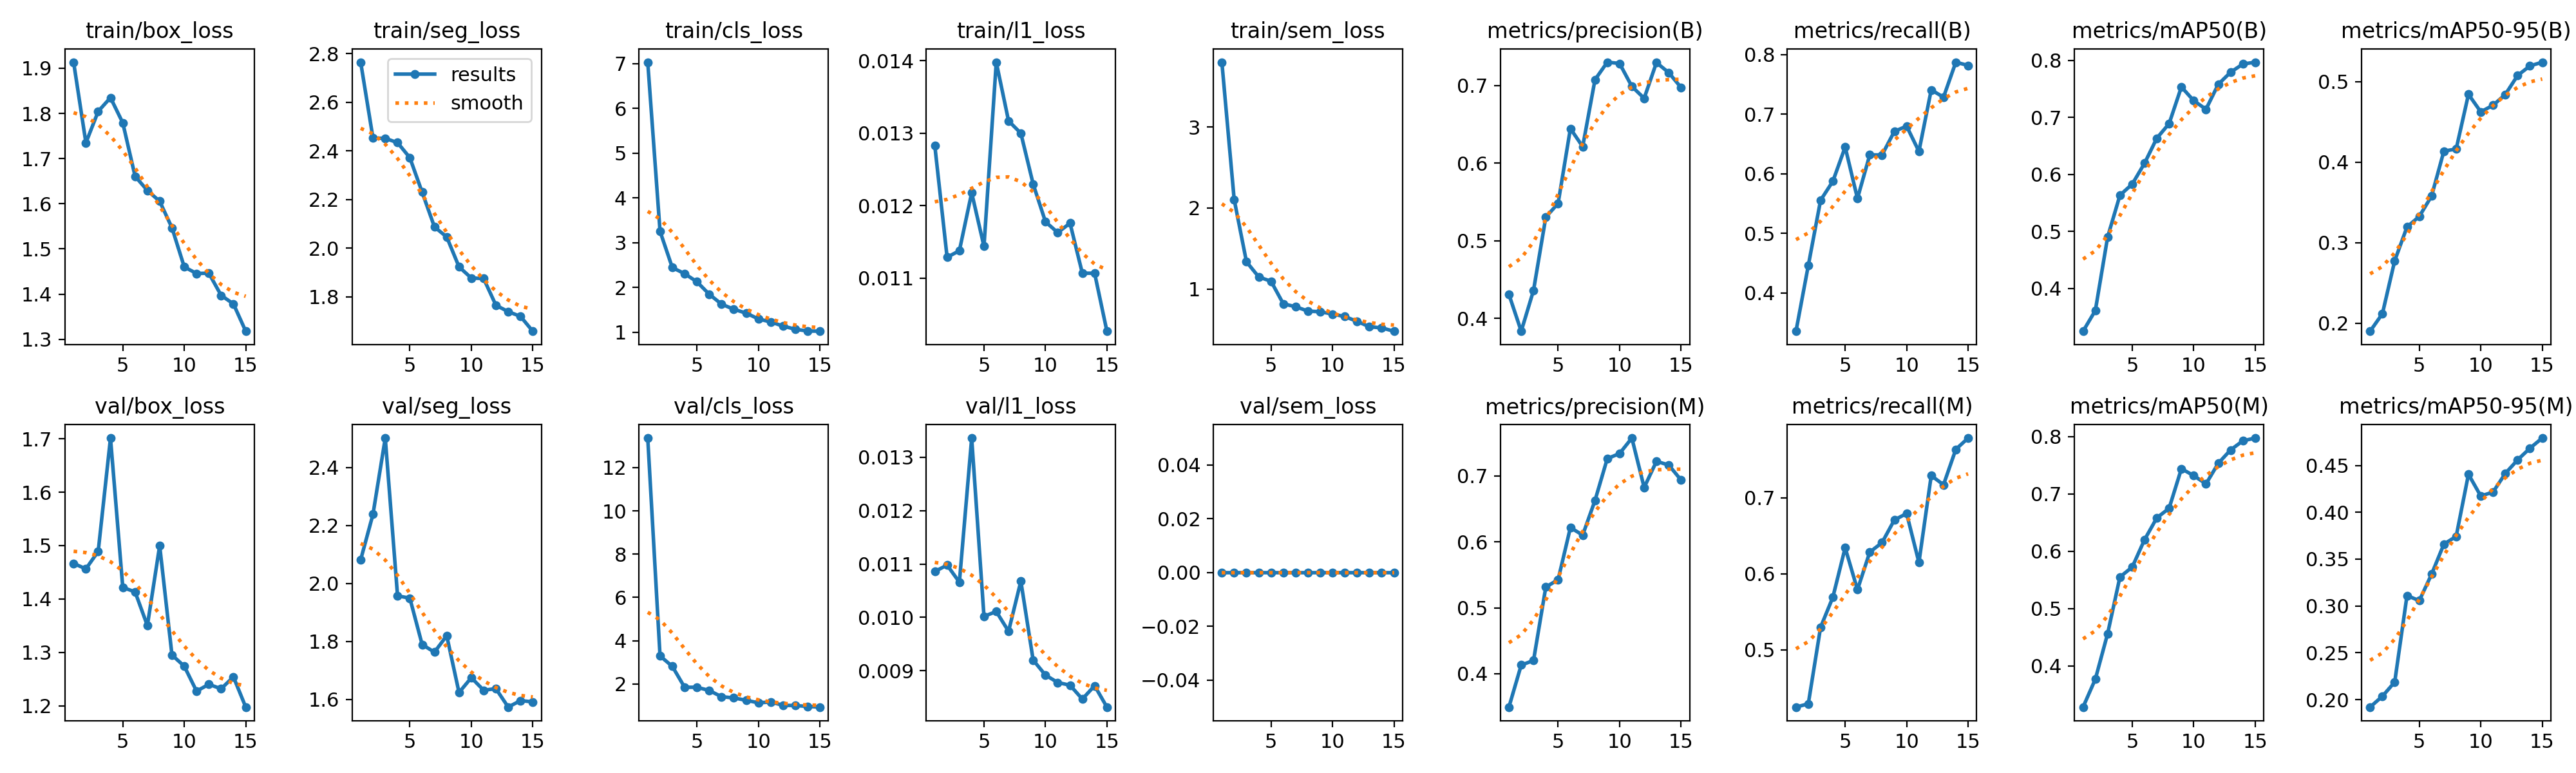

In [ ]:
#@title Curvas de entrenamiento de YOLO { display-mode: "form" }
from IPython.display import Image, display
display(Image(filename=str(YOLO_DIR / "results.png"), width=1000))

In [ ]:
#@title Métricas de YOLO en el conjunto de prueba { display-mode: "form" }
yolo = YOLO(YOLO_BEST)
m = yolo.val(data=str(yaml_path), split="test", imgsz=YOLO_IMGSZ, plots=False)
tabla_yolo = pd.DataFrame({
    "Métrica": ["Precision (cajas)", "Recall (cajas)", "mAP50 (cajas)", "mAP50-95 (cajas)",
                "mAP50 (máscaras)", "mAP50-95 (máscaras)"],
    "Valor": [m.box.mp, m.box.mr, m.box.map50, m.box.map, m.seg.map50, m.seg.map]}).round(3)
tabla_yolo

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n-seg summary (fused): 137 layers, 2,704,269 parameters, 0 gradients, 9.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1982.5±411.8 MB/s, size: 81.4 KB)
val: Scanning /content/yolo_data/labels/test... 320 images, 80 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 320/320 2.0Kit/s 0.2s
val: New cache created: /content/yolo_data/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 20/20 8.5it/s 2.4s
                   all        320        240      0.734      0.668      0.725      0.464      0.743      0.677       0.74      0.408
                glioma         80         80      0.611       0.53      0.624      0.418       0.64      0.555      0.651      0.377
            meningioma         80         80      0.804        0.7      0.756      0.451      0.804        0.7       0.7

,Métrica,Valor
0,Precision (cajas),0.734
1,Recall (cajas),0.668
2,mAP50 (cajas),0.725
3,mAP50-95 (cajas),0.464
4,mAP50 (máscaras),0.740
5,mAP50-95 (máscaras),0.408


In [ ]:
#@title **code** Función para ampliar la caja (caja → recorte con margen) { display-mode: "form" }
# CAMBIO: esta función se movió aquí (antes estaba en la sección 8) porque ahora el recorte se calcula
#         ANTES de cargar TensorFlow (se necesita para sacar los features de YOLO).
def crop_box(box, shape, margin):
    """Expande la caja (x1,y1,x2,y2) un porcentaje 'margin' y la limita a la imagen."""
    x1, y1, x2, y2 = box; h, w = shape
    bw, bh = x2 - x1, y2 - y1
    x1 = int(max(0, x1 - margin * bw)); x2 = int(min(w, x2 + margin * bw))
    y1 = int(max(0, y1 - margin * bh)); y2 = int(min(h, y2 + margin * bh))
    return x1, y1, max(x2, x1 + 2), max(y2, y1 + 2)

In [ ]:
#@title Guardar las detecciones de YOLO sobre el conjunto de prueba (antes de cargar TensorFlow) { display-mode: "form" }
# CAMBIO 1: ahora se guarda SIEMPRE la caja más confiable (aunque la confianza sea baja), porque la U-Net
#           va a recibir el recorte de esa caja SIN IMPORTAR lo que YOLO haya predicho (clase o máscara).
# CAMBIO 2: se guarda también el recorte de FEATURES de YOLO (mapa P3) dentro de esa caja, con RoIAlign.
from torchvision.ops import roi_align
import gc

S = YOLO_IMGSZ
_cap = {}
def _guardar_features(modulo, entradas):
    # entradas[0] = lista [P3, P4, P5] que recibe la cabeza de YOLO; P3 = mapa de features con stride 8 (S/8 x S/8)
    _cap["f"] = entradas[0][0].detach()

yolo = YOLO(YOLO_BEST)
yolo.model.model[-1].register_forward_pre_hook(_guardar_features)       # se registra ANTES del primer predict
yolo.predict(np.zeros((S, S, 3), np.uint8), imgsz=S, verbose=False)     # predict de calentamiento
assert "f" in _cap, "No se capturaron los features de YOLO: el hook debe registrarse antes del primer predict."

def feat_patch(box_s):
    """Recorta con RoIAlign el mapa de features P3 dentro de una caja (coordenadas de la imagen S x S)."""
    with torch.no_grad():
        f = _cap["f"].float()                                           # (1, C, S/8, S/8)
        b = torch.tensor([[0.0] + [float(v) for v in box_s]], dtype=torch.float32, device=f.device)
        out = roi_align(f, b, output_size=(FEAT_SIZE, FEAT_SIZE), spatial_scale=f.shape[-1] / S,
                        sampling_ratio=2, aligned=True)
    return out[0].permute(1, 2, 0).cpu().numpy().astype(np.float16)    # (FEAT_SIZE, FEAT_SIZE, C)

test_items = [i for i in items if i["split"] == "test"]
dets = {}   # imagen -> detección MÁS confiable (clase, confianza, caja, polígono, features) o None si YOLO no devuelve ninguna caja
for it in tqdm(test_items):
    im = cv2.imread(str(it["img"])); H, W = im.shape[:2]
    esc = np.array([W / S, H / S, W / S, H / S])                        # de coordenadas S x S a las de la imagen original
    r = yolo.predict(cv2.resize(im, (S, S)), conf=YOLO_CONF_CROP, imgsz=S, verbose=False)[0]
    if r.boxes is None or len(r.boxes) == 0:
        dets[it["img"]] = None; continue
    k = int(r.boxes.conf.argmax())
    box = r.boxes.xyxy[k].cpu().numpy() * esc
    poly = None
    if r.masks is not None and len(r.masks.xy[k]) > 2:
        poly = (r.masks.xy[k] * esc[:2]).astype(np.int32)
    ebox = np.array(crop_box(box, (H, W), MARGIN))                      # caja ampliada: la MISMA que verá la U-Net
    dets[it["img"]] = dict(cls=int(r.boxes.cls[k]), conf=float(r.boxes.conf[k]), box=box, poly=poly,
                           feat=feat_patch(ebox / esc))

n_sin = sum(v is None for v in dets.values())
n_baja = sum(v is not None and v["conf"] < YOLO_CONF for v in dets.values())
print("Detecciones guardadas:", len(dets), "| sin ninguna caja:", n_sin, f"| con caja pero confianza < {YOLO_CONF}:", n_baja)
print("Forma del recorte de features:", next(v for v in dets.values() if v is not None)["feat"].shape)

  0%|          | 0/320 [00:00<?, ?it/s]

Detecciones guardadas: 320 | sin ninguna caja: 53 | con caja pero confianza < 0.25: 48
Forma del recorte de features: (32, 32, 64)


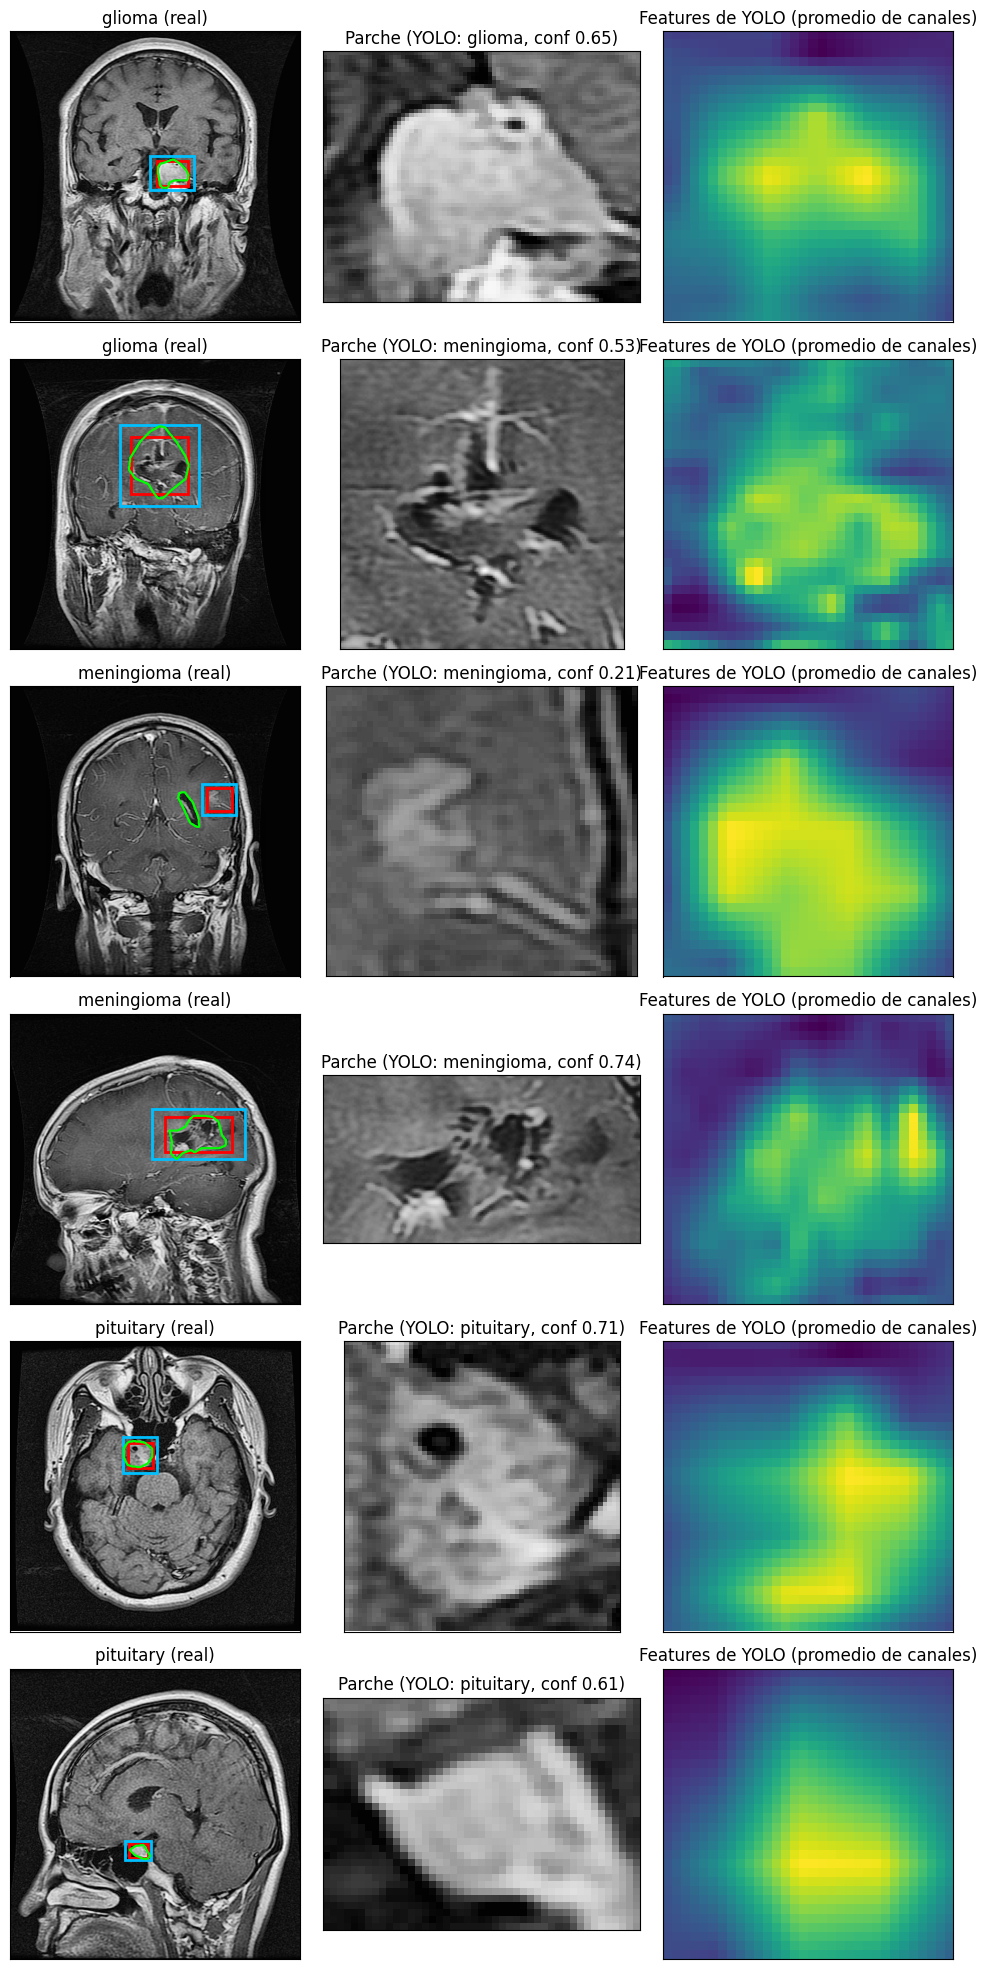

In [ ]:
#@title Mostrar la caja de YOLO y el recorte que recibirá la U-Net { display-mode: "form" }
# NUEVO (recomendación del profe: "mostrar los parches")
# Verde = máscara real | Rojo = caja de YOLO | Azul = recorte final (caja + margen) que entra a la U-Net
from matplotlib.patches import Rectangle
muestras = []
for c in range(3):                                   # 2 ejemplos por clase de tumor
    muestras += [i for i in test_items if i["cls"] == c][:2]
fig, ax = plt.subplots(len(muestras), 3, figsize=(10, 3.3 * len(muestras)))
for r_, it in enumerate(muestras):
    im = cv2.imread(str(it["img"])); H, W = im.shape[:2]; gt = read_mask(it, (H, W)); det = dets[it["img"]]
    ax[r_, 0].imshow(im[..., ::-1]); ax[r_, 0].contour(gt, levels=[0.5], colors="lime")
    ax[r_, 0].set_title(f"{NAMES[it['cls']]} (real)")
    if det is None:
        ax[r_, 1].set_title("YOLO no devolvió ninguna caja")
    else:
        x1, y1, x2, y2 = det["box"]; ex1, ey1, ex2, ey2 = crop_box(det["box"], (H, W), MARGIN)
        ax[r_, 0].add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="red", lw=2))
        ax[r_, 0].add_patch(Rectangle((ex1, ey1), ex2 - ex1, ey2 - ey1, fill=False, ec="deepskyblue", lw=2))
        ax[r_, 1].imshow(im[ey1:ey2, ex1:ex2][..., ::-1])
        ax[r_, 1].set_title(f"Parche (YOLO: {NAMES[det['cls']]}, conf {det['conf']:.2f})")
        ax[r_, 2].imshow(det["feat"].astype(np.float32).mean(-1), cmap="viridis")
        ax[r_, 2].set_title("Features de YOLO (promedio de canales)")
    for a in ax[r_]: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/parches_yolo.png", dpi=200, bbox_inches="tight"); plt.show()

In [ ]:
#@title Cajas de recorte reales y features de YOLO para entrenar la U-Net { display-mode: "form" }
# NUEVO: para cada imagen CON tumor se calcula la caja real (a partir de la máscara) y el recorte de features de YOLO en esa caja.
#        train: margen aleatorio 10-40 %  |  val/test: margen fijo (MARGIN)
# OJO: YOLO se entrenó con las imágenes de train, así que sus features en train son "mejores" que en val/test.
rng_m = random.Random(SEED)
for it in tqdm([i for i in items if i["cls"] != 3 and i["split"] in ("train", "val", "test")]):
    im = cv2.imread(str(it["img"])); H, W = im.shape[:2]
    mk_ = read_mask(it, (H, W)); ys, xs = np.where(mk_ > 0)
    if len(xs) == 0: continue
    mg = rng_m.uniform(0.1, 0.4) if it["split"] == "train" else MARGIN
    it["pbox"] = crop_box((xs.min(), ys.min(), xs.max() + 1, ys.max() + 1), (H, W), mg)
    yolo.predict(cv2.resize(im, (S, S)), conf=YOLO_CONF_CROP, imgsz=S, verbose=False)   # solo para que el hook capture los features
    it["feat"] = feat_patch(np.array(it["pbox"]) / np.array([W / S, H / S, W / S, H / S]))

del yolo; gc.collect(); torch.cuda.empty_cache()     # liberamos YOLO antes de cargar TensorFlow
print("Parches con caja real y features:", sum("pbox" in i for i in items))
print("Forma de un recorte de features:", next(i for i in items if "feat" in i)["feat"].shape)

  0%|          | 0/1380 [00:00<?, ?it/s]

Parches con caja real y features: 1380
Forma de un recorte de features: (32, 32, 64)


## 8. Etapa 2: U-Net sobre el parche recortado

### Preparar los parches
Para entrenar se recorta la región del tumor real (con margen aleatorio entre 10 % y 40 % en entrenamiento, para simular los errores de la caja de YOLO). En validación y prueba el margen es fijo.

**Novedad (recomendaciones del profe):**
- A la U-Net le llega el recorte de la **caja de YOLO sin importar la clase, la confianza ni la máscara** que YOLO haya predicho. De YOLO solo se usa la caja.
- Además del recorte de la **imagen**, se prueba recortar los **features** de YOLO (mapa interno P3) dentro de la misma caja.
- Se **muestran los parches** que recibe la U-Net.

In [ ]:
#@title Cargar TensorFlow/Keras (se importa aquí para no chocar con YOLO) { display-mode: "form" }
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, BatchNormalization, Activation, Dropout
from tensorflow.keras.layers import Conv2D, Conv2DTranspose, MaxPooling2D, concatenate, UpSampling2D   # CAMBIO: + UpSampling2D
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.metrics import BinaryIoU

In [ ]:
#@title **code** Función para recortar parches { display-mode: "form" }
# CAMBIO: crop_box ya se definió arriba y las cajas (it["pbox"]) y los features (it["feat"]) ya se calcularon antes de cargar TensorFlow.
#         make_patches ahora usa esas cajas y devuelve también los features (F) y la lista de muestras (I).
def make_patches(split):
    """Parches de tumores reales. Devuelve X (N,P,P,3) uint8, y (N,P,P,1) uint8, F (N,FEAT,FEAT,C) float16 e I (lista de muestras)."""
    X, Y, F, I = [], [], [], []
    for it in tqdm([i for i in items if i["split"] == split and "pbox" in i], desc=split):
        im = cv2.imread(str(it["img"])); mk = read_mask(it, im.shape[:2])
        x1, y1, x2, y2 = it["pbox"]
        p = cv2.resize(im[y1:y2, x1:x2], (PATCH, PATCH), interpolation=cv2.INTER_LINEAR)
        q = cv2.resize(mk[y1:y2, x1:x2], (PATCH, PATCH), interpolation=cv2.INTER_NEAREST)
        X.append(p[..., ::-1]); Y.append(q); F.append(it["feat"]); I.append(it)          # BGR -> RGB
    return np.array(X, np.uint8), np.array(Y, np.uint8)[..., None], np.array(F, np.float16), I

X_tr, y_tr, F_tr, I_tr = make_patches("train")
X_val, y_val, F_val, I_val = make_patches("val")
X_te, y_te, F_te, I_te = make_patches("test")
print(X_tr.shape, y_tr.shape, F_tr.shape, X_val.shape, X_te.shape)

train:   0%|          | 0/900 [00:00<?, ?it/s]

val:   0%|          | 0/240 [00:00<?, ?it/s]

test:   0%|          | 0/240 [00:00<?, ?it/s]

(900, 128, 128, 3) (900, 128, 128, 1) (900, 32, 32, 64) (240, 128, 128, 3) (240, 128, 128, 3)


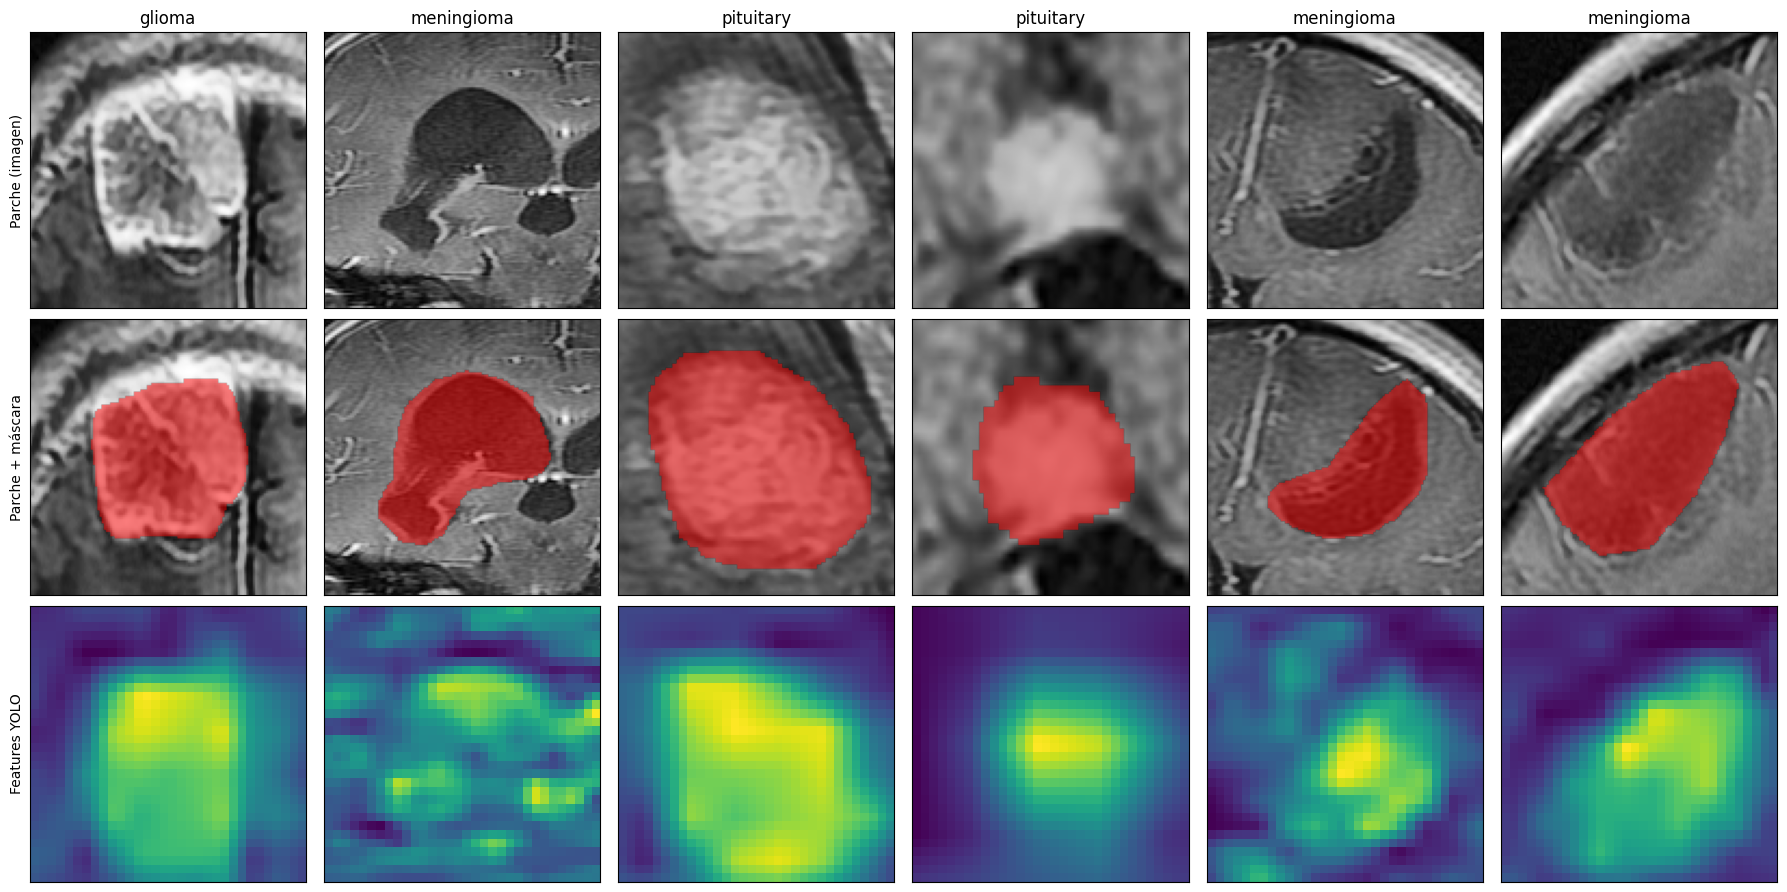

In [ ]:
#@title Mostrar los parches de entrenamiento (imagen, máscara y features) { display-mode: "form" }
# NUEVO (recomendación del profe: "mostrar los parches"): lo que realmente recibe la U-Net al entrenar
idx = [next(k for k, it in enumerate(I_tr) if it["cls"] == c) for c in range(3)] + random.Random(SEED).sample(range(len(X_tr)), 3)
fig, ax = plt.subplots(3, len(idx), figsize=(3 * len(idx), 9))
for j, k in enumerate(idx):
    ax[0, j].imshow(X_tr[k]); ax[0, j].set_title(NAMES[I_tr[k]["cls"]])
    ax[1, j].imshow(X_tr[k]); ax[1, j].imshow(np.ma.masked_where(y_tr[k, ..., 0] == 0, y_tr[k, ..., 0]), alpha=0.5, cmap="autumn")
    ax[2, j].imshow(F_tr[k].astype(np.float32).mean(-1), cmap="viridis")
for a, t in zip(ax[:, 0], ["Parche (imagen)", "Parche + máscara", "Features YOLO"]): a.set_ylabel(t)
for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/parches_entrenamiento.png", dpi=200, bbox_inches="tight"); plt.show()

In [ ]:
#@title **code** Bloque de dos convoluciones de la U-Net { display-mode: "form" }
def conv2d_block(input_tensor, n_filters, kernel_size=3, batchnorm=True):
    """Dos capas convolucionales (Conv -> BatchNorm -> ReLU) seguidas."""
    x = Conv2D(n_filters, (kernel_size, kernel_size), kernel_initializer='he_normal', padding='same')(input_tensor)
    if batchnorm: x = BatchNormalization()(x)
    x = Activation('relu')(x)

    x = Conv2D(n_filters, (kernel_size, kernel_size), kernel_initializer='he_normal', padding='same')(x)
    if batchnorm: x = BatchNormalization()(x)
    x = Activation('relu')(x)
    return x

In [ ]:
#@title **code** Función que construye la U-Net { display-mode: "form" }
def get_unet(input_img, n_filters=16, dropout=0.1, batchnorm=True, inputs=None):   # CAMBIO: parámetro 'inputs' (para entradas con varios tensores)
    # Camino contractivo (encoder): reduce la resolución y aumenta los filtros
    c1 = conv2d_block(input_img, n_filters * 1, batchnorm=batchnorm)
    p1 = Dropout(dropout)(MaxPooling2D((2, 2))(c1))
    c2 = conv2d_block(p1, n_filters * 2, batchnorm=batchnorm)
    p2 = Dropout(dropout)(MaxPooling2D((2, 2))(c2))
    c3 = conv2d_block(p2, n_filters * 4, batchnorm=batchnorm)
    p3 = Dropout(dropout)(MaxPooling2D((2, 2))(c3))
    c4 = conv2d_block(p3, n_filters * 8, batchnorm=batchnorm)
    p4 = Dropout(dropout)(MaxPooling2D((2, 2))(c4))

    # Cuello de botella
    c5 = conv2d_block(p4, n_filters * 16, batchnorm=batchnorm)

    # Camino expansivo (decoder): recupera la resolución usando las conexiones skip
    u6 = Conv2DTranspose(n_filters * 8, (3, 3), strides=(2, 2), padding='same')(c5)
    u6 = Dropout(dropout)(concatenate([u6, c4]))
    c6 = conv2d_block(u6, n_filters * 8, batchnorm=batchnorm)

    u7 = Conv2DTranspose(n_filters * 4, (3, 3), strides=(2, 2), padding='same')(c6)
    u7 = Dropout(dropout)(concatenate([u7, c3]))
    c7 = conv2d_block(u7, n_filters * 4, batchnorm=batchnorm)

    u8 = Conv2DTranspose(n_filters * 2, (3, 3), strides=(2, 2), padding='same')(c7)
    u8 = Dropout(dropout)(concatenate([u8, c2]))
    c8 = conv2d_block(u8, n_filters * 2, batchnorm=batchnorm)

    u9 = Conv2DTranspose(n_filters * 1, (3, 3), strides=(2, 2), padding='same')(c8)
    u9 = Dropout(dropout)(concatenate([u9, c1]))
    c9 = conv2d_block(u9, n_filters * 1, batchnorm=batchnorm)

    # Salida: 1 canal con sigmoide (probabilidad de tumor por píxel)
    outputs = Conv2D(1, (1, 1), activation='sigmoid')(c9)
    return Model(inputs=inputs if inputs is not None else [input_img], outputs=[outputs])   # CAMBIO

In [ ]:
#@title **code** Pérdida BCE + Dice y compilación { display-mode: "form" }
# BCE + Dice ayuda con el desbalance entre fondo y tumor
def dice_loss(y_true, y_pred, smooth=1.0):
    y_true = tf.cast(y_true, tf.float32)
    inter = tf.reduce_sum(y_true * y_pred, axis=[1, 2, 3])
    union = tf.reduce_sum(y_true, axis=[1, 2, 3]) + tf.reduce_sum(y_pred, axis=[1, 2, 3])
    return 1.0 - tf.reduce_mean((2.0 * inter + smooth) / (union + smooth))

def bce_dice_loss(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32)
    bce = tf.keras.losses.binary_crossentropy(y_true, y_pred)
    return tf.reduce_mean(bce) + dice_loss(y_true, y_pred)

input_img = Input((PATCH, PATCH, 3), name='img')
unet = get_unet(input_img, n_filters=UNET_FILTERS, dropout=UNET_DROPOUT, batchnorm=True)
unet.compile(optimizer=Adam(learning_rate=UNET_LR), loss=bce_dice_loss,
             metrics=[BinaryIoU(target_class_ids=[1], threshold=0.5)])
unet.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ img (InputLayer)    │ (None, 128, 128,  │          0 │ -                 │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │        448 │ img[0][0]         │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128, 128,  │         64 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │      2,320 │ activation[0][0]  │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │         64 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ activation_1[0][… │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64, 64,    │          0 │ max_pooling2d[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │      4,640 │ dropout[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        128 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │      9,248 │ activation_2[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        128 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 32, 32,    │          0 │ activation_3[0][… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 32, 32,    │          0 │ max_pooling2d_1[

 Total params: 2,164,593 (8.26 MB)

 Trainable params: 2,161,649 (8.25 MB)

 Non-trainable params: 2,944 (11.50 KB)

### Entrenamiento de la U-Net
Aumento de datos simple (giros horizontales y verticales aplicados igual a imagen y máscara), *early stopping* sobre el IoU de validación y reducción del learning rate cuando la pérdida se estanca.

In [ ]:
def augment(x, y):
    if tf.random.uniform(()) > 0.5:
        x, y = tf.image.flip_left_right(x), tf.image.flip_left_right(y)
    if tf.random.uniform(()) > 0.5:
        x, y = tf.image.flip_up_down(x), tf.image.flip_up_down(y)
    return x, y

def to_float(x, y):
    return tf.cast(x, tf.float32) / 255.0, tf.cast(y, tf.float32)

train_ds = (tf.data.Dataset.from_tensor_slices((X_tr, y_tr)).shuffle(len(X_tr), seed=SEED)
            .map(to_float).map(augment, num_parallel_calls=tf.data.AUTOTUNE)
            .batch(UNET_BATCH).prefetch(tf.data.AUTOTUNE))
val_ds = (tf.data.Dataset.from_tensor_slices((X_val, y_val)).map(to_float)
          .batch(UNET_BATCH).prefetch(tf.data.AUTOTUNE))

UNET_W = f"{RESULTS_DIR}/best_unet.weights.h5"
callbacks = [
    EarlyStopping(monitor='val_binary_io_u', mode='max', patience=15, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6, verbose=1),
    ModelCheckpoint(UNET_W, monitor='val_binary_io_u', mode='max', save_best_only=True,
                    save_weights_only=True, verbose=1),
]
results = unet.fit(train_ds, validation_data=val_ds, epochs=UNET_EPOCHS, callbacks=callbacks)

Epoch 1/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 808ms/step - binary_io_u: 0.4516 - loss: 1.0218
Epoch 1: val_binary_io_u improved from None to 0.67619, saving model to /content/IA2_proyecto/best_unet.weights.h5

Epoch 1: finished saving model to /content/IA2_proyecto/best_unet.weights.h5
57/57 ━━━━━━━━━━━━━━━━━━━━ 105s 861ms/step - binary_io_u: 0.6035 - loss: 0.7958 - val_binary_io_u: 0.6762 - val_loss: 1.1935 - learning_rate: 0.0010
Epoch 2/30
56/57 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - binary_io_u: 0.7499 - loss: 0.5098
Epoch 2: val_binary_io_u did not improve from 0.67619
57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - binary_io_u: 0.7572 - loss: 0.4809 - val_binary_io_u: 0.6534 - val_loss: 1.2467 - learning_rate: 0.0010
Epoch 3/30
56/57 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - binary_io_u: 0.7760 - loss: 0.4142
Epoch 3: val_binary_io_u improved from 0.67619 to 0.75373, saving model to /content/IA2_proyecto/best_unet.weights.h5

Epoch 3: finished saving model to /content/IA2_proyecto/best_unet.weights.

### Curvas de pérdida y métrica

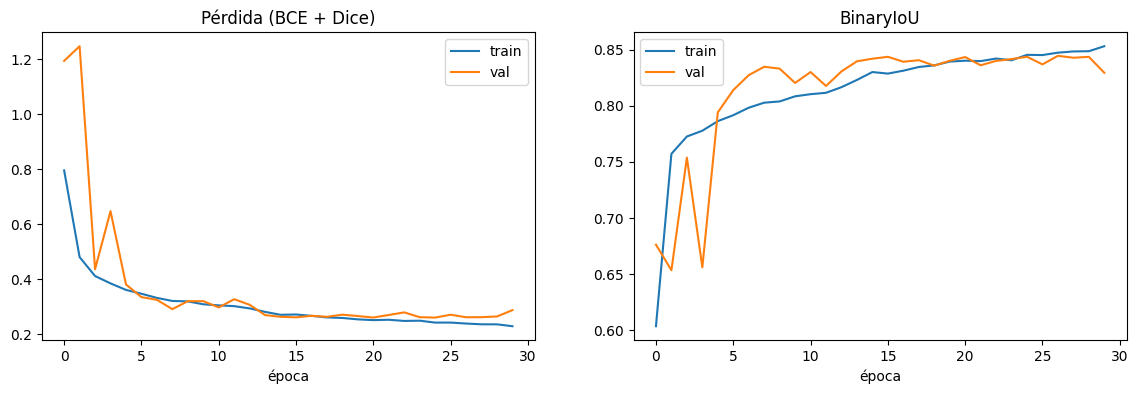

In [ ]:
metric_key = [k for k in results.history if 'io_u' in k and not k.startswith('val_')][0]
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(results.history['loss'], label='train'); ax[0].plot(results.history['val_loss'], label='val')
ax[0].set_title('Pérdida (BCE + Dice)'); ax[0].set_xlabel('época'); ax[0].legend()
ax[1].plot(results.history[metric_key], label='train'); ax[1].plot(results.history['val_' + metric_key], label='val')
ax[1].set_title('BinaryIoU'); ax[1].set_xlabel('época'); ax[1].legend()
plt.savefig(f"{RESULTS_DIR}/curvas_unet.png", dpi=200, bbox_inches="tight"); plt.show()

In [ ]:
#@title Métricas de la U-Net sobre parches de prueba (recorte con la caja real) { display-mode: "form" }
def dice_iou(p, g):
    p, g = p.astype(bool), g.astype(bool)
    inter = (p & g).sum(); s = p.sum() + g.sum(); u = (p | g).sum()
    return (2 * inter / s if s > 0 else 1.0), (inter / u if u > 0 else 1.0)

pred_te = (unet.predict(X_te.astype("float32") / 255.0, verbose=0) > 0.5).astype(np.uint8)
res = np.array([dice_iou(p, g) for p, g in zip(pred_te, y_te)])
print(f"U-Net en parches de prueba -> Dice: {res[:,0].mean():.3f} | IoU: {res[:,1].mean():.3f}")

U-Net en parches de prueba -> Dice: 0.902 | IoU: 0.826


## 8b. U-Net con los *features* de YOLO (recomendación del profe)

En lugar de recortar solo la **imagen original**, se recorta el **mapa de features** que YOLO calcula por dentro (capa P3, con *RoIAlign*) usando la misma caja. Se comparan tres entradas para la U-Net:

| Entrada | Qué recibe la U-Net |
|---|---|
| `imagen` | Parche de la imagen (el modelo que ya entrenamos arriba) |
| `features` | Solo el recorte de features de YOLO (se amplía de 32×32 al tamaño del parche) |
| `imagen+features` | Ambos, concatenados por canales |

La idea: los features de YOLO ya "saben" qué es un tumor, así que pueden dar a la U-Net información más rica que los píxeles.

In [ ]:
#@title **code** U-Net con entrada de features (y de imagen + features) { display-mode: "form" }
assert PATCH % FEAT_SIZE == 0, "PATCH debe ser múltiplo de FEAT_SIZE"
C_FEAT = F_tr.shape[-1]
F_MU = F_tr.astype(np.float32).mean((0, 1, 2)); F_SD = F_tr.astype(np.float32).std((0, 1, 2)) + 1e-6   # normalización por canal (solo con train)
def norm_f(f): return (f.astype(np.float32) - F_MU) / F_SD

def build_unet(modo):
    """modo: 'features' (solo features) o 'imagen+features' (imagen y features concatenados)."""
    img_in = Input((PATCH, PATCH, 3), name='img')
    feat_in = Input((FEAT_SIZE, FEAT_SIZE, C_FEAT), name='feat')
    up = UpSampling2D(size=(PATCH // FEAT_SIZE, PATCH // FEAT_SIZE), interpolation='bilinear')(feat_in)   # features -> tamaño del parche
    if modo == 'features': x, entradas = up, [feat_in]
    else:                  x, entradas = concatenate([img_in, up]), [img_in, feat_in]
    m = get_unet(x, n_filters=UNET_FILTERS, dropout=UNET_DROPOUT, batchnorm=True, inputs=entradas)
    m.compile(optimizer=Adam(learning_rate=UNET_LR), loss=bce_dice_loss,
              metrics=[BinaryIoU(target_class_ids=[1], threshold=0.5, name='binary_io_u')])   # nombre fijo: si no, Keras lo renombra a binary_io_u_1/_2 y los callbacks no lo encuentran
    return m

def make_ds(X, F, y, modo, train):
    """tf.data con imagen, features y máscara; los giros se aplican igual a los tres."""
    def prep(x, f, m):
        return tf.cast(x, tf.float32) / 255.0, (tf.cast(f, tf.float32) - F_MU) / F_SD, tf.cast(m, tf.float32)
    def aug(x, f, m):
        if tf.random.uniform(()) > 0.5:
            x, f, m = tf.image.flip_left_right(x), tf.image.flip_left_right(f), tf.image.flip_left_right(m)
        if tf.random.uniform(()) > 0.5:
            x, f, m = tf.image.flip_up_down(x), tf.image.flip_up_down(f), tf.image.flip_up_down(m)
        return x, f, m
    def pack(x, f, m):
        d = {}
        if 'imagen' in modo: d['img'] = x
        if 'features' in modo: d['feat'] = f
        return d, m
    ds = tf.data.Dataset.from_tensor_slices((X, F, y))
    if train: ds = ds.shuffle(len(X), seed=SEED)
    ds = ds.map(prep)
    if train: ds = ds.map(aug, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.map(pack).batch(UNET_BATCH).prefetch(tf.data.AUTOTUNE)

In [ ]:
# Entrenar las dos variantes nuevas (la de 'imagen' ya se entrenó arriba, es la variable `unet`)
modelos = {"imagen": unet}
historiales = {"imagen": results}
for modo in ["features", "imagen+features"]:
    print("\n=== Entrenando la U-Net con entrada:", modo, "===")
    mdl = build_unet(modo)
    cbs = [EarlyStopping(monitor='val_binary_io_u', mode='max', patience=15, restore_best_weights=True, verbose=1),
           ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6, verbose=1),
           ModelCheckpoint(f"{RESULTS_DIR}/best_unet_{modo.replace('+', '_')}.weights.h5", monitor='val_binary_io_u',
                           mode='max', save_best_only=True, save_weights_only=True)]
    historiales[modo] = mdl.fit(make_ds(X_tr, F_tr, y_tr, modo, True),
                                validation_data=make_ds(X_val, F_val, y_val, modo, False),
                                epochs=UNET_EPOCHS, callbacks=cbs, verbose=2)
    modelos[modo] = mdl


=== Entrenando la U-Net con entrada: features ===
Epoch 1/30
57/57 - 56s - 988ms/step - binary_io_u: 0.7272 - loss: 0.6013 - val_binary_io_u: 0.6491 - val_loss: 2.8018 - learning_rate: 0.0010
Epoch 2/30
57/57 - 4s - 67ms/step - binary_io_u: 0.8124 - loss: 0.4017 - val_binary_io_u: 0.8206 - val_loss: 0.5212 - learning_rate: 0.0010
Epoch 3/30
57/57 - 4s - 72ms/step - binary_io_u: 0.8216 - loss: 0.3440 - val_binary_io_u: 0.8237 - val_loss: 0.4470 - learning_rate: 0.0010
Epoch 4/30
57/57 - 4s - 68ms/step - binary_io_u: 0.8219 - loss: 0.3175 - val_binary_io_u: 0.8297 - val_loss: 0.3695 - learning_rate: 0.0010
Epoch 5/30
57/57 - 4s - 67ms/step - binary_io_u: 0.8264 - loss: 0.2984 - val_binary_io_u: 0.8340 - val_loss: 0.3604 - learning_rate: 0.0010
Epoch 6/30
57/57 - 4s - 72ms/step - binary_io_u: 0.8296 - loss: 0.2857 - val_binary_io_u: 0.8425 - val_loss: 0.3185 - learning_rate: 0.0010
Epoch 7/30
57/57 - 4s - 70ms/step - binary_io_u: 0.8294 - loss: 0.2806 - val_binary_io_u: 0.8426 - val_loss

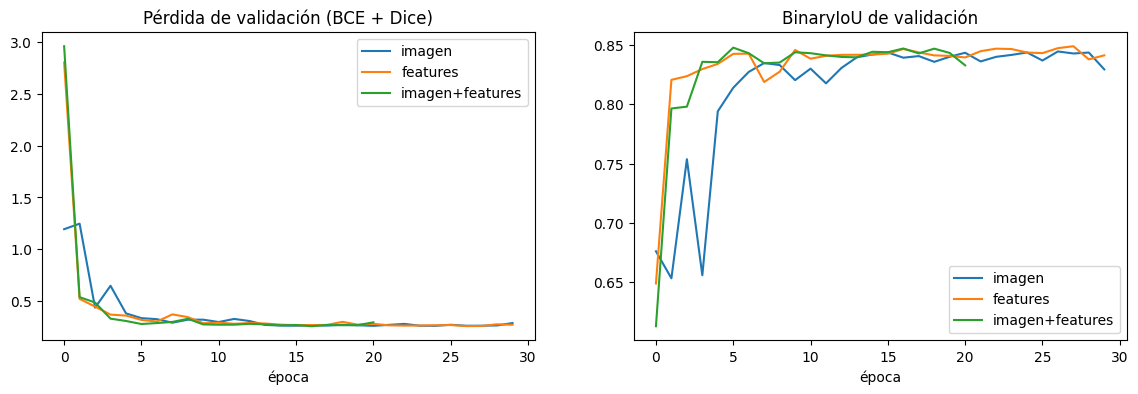

In [ ]:
#@title Curvas de validación de las tres entradas { display-mode: "form" }
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for modo, h in historiales.items():
    k = [k for k in h.history if 'io_u' in k and not k.startswith('val_')][0]
    ax[0].plot(h.history['val_loss'], label=modo); ax[1].plot(h.history['val_' + k], label=modo)
ax[0].set_title('Pérdida de validación (BCE + Dice)'); ax[1].set_title('BinaryIoU de validación')
for a in ax: a.set_xlabel('época'); a.legend()
plt.savefig(f"{RESULTS_DIR}/curvas_unet_variantes.png", dpi=200, bbox_inches="tight"); plt.show()

In [ ]:
#@title Métricas sobre parches de prueba con la caja REAL (cota superior) { display-mode: "form" }
def predecir_parches(modelo, modo, X, F):
    ins = {}
    if 'imagen' in modo: ins['img'] = X.astype('float32') / 255.0
    if 'features' in modo: ins['feat'] = norm_f(F)
    return (modelo.predict(ins, verbose=0) > 0.5).astype(np.uint8)

filas = []
for modo, mdl in modelos.items():
    r_ = np.array([dice_iou(a, b) for a, b in zip(predecir_parches(mdl, modo, X_te, F_te), y_te)])
    filas.append({"Entrada de la U-Net": modo, "Dice": r_[:, 0].mean(), "IoU": r_[:, 1].mean()})
tabla_parches = pd.DataFrame(filas).round(3)
display(tabla_parches)

,Entrada de la U-Net,Dice,IoU
0,imagen,0.902,0.826
1,features,0.906,0.833
2,imagen+features,0.908,0.835


## 9. Resultados: pipeline completo (YOLO → recorte → U-Net)

Ahora sí se usa el pipeline real: la caja viene de **YOLO**, no de la máscara real. Comparamos **solo YOLO** contra **YOLO + U-Net** en el conjunto de prueba.

**Cambio:** la U-Net recibe el recorte de la caja de YOLO **sin importar** la clase, la confianza ni la máscara que YOLO haya predicho (con tal de que YOLO devuelva alguna caja). La clase final sigue saliendo de YOLO, solo si su confianza es ≥ `YOLO_CONF`.

In [ ]:
#@title **code** Función del pipeline completo { display-mode: "form" }
# CAMBIO: la U-Net recibe el recorte de la caja de YOLO SIN IMPORTAR la clase, la confianza ni la máscara que YOLO haya predicho.
#         YOLO solo aporta la CAJA (y sus features). La CLASE sigue saliendo de YOLO, pero solo si conf >= YOLO_CONF.
def segmentar(im, det, modo):
    """Recorta la caja de YOLO (ampliada con MARGIN) y la segmenta con la U-Net de entrada 'modo'."""
    H, W = im.shape[:2]; full = np.zeros((H, W), np.uint8)
    if det is None: return full                                    # YOLO no devolvió ninguna caja
    x1, y1, x2, y2 = crop_box(det["box"], (H, W), MARGIN)
    ins = {}
    if "imagen" in modo:
        ins["img"] = (cv2.resize(im[y1:y2, x1:x2], (PATCH, PATCH))[..., ::-1].astype("float32") / 255.0)[None]
    if "features" in modo:
        ins["feat"] = norm_f(det["feat"])[None]
    out = modelos[modo](ins, training=False).numpy()[0, :, :, 0]
    full[y1:y2, x1:x2] = cv2.resize(out, (x2 - x1, y2 - y1)) > 0.5  # de vuelta al tamaño del recorte
    return full

def pipeline(im, det):
    """Devuelve (clase, máscara de YOLO, {entrada: máscara de la U-Net})."""
    H, W = im.shape[:2]; yolo_m = np.zeros((H, W), np.uint8)
    if det is None or det["conf"] < YOLO_CONF:
        cls = 3                                                    # YOLO no está seguro -> 'sin tumor' (máscara de YOLO vacía)
    else:
        cls = det["cls"]
        if det["poly"] is not None:
            cv2.fillPoly(yolo_m, [det["poly"]], 1)                 # máscara gruesa de YOLO
    return cls, yolo_m, {modo: segmentar(im, det, modo) for modo in modelos}

In [ ]:
#@title Evaluar en el conjunto de prueba completo { display-mode: "form" }
SUF = {"imagen": "unet", "features": "feat", "imagen+features": "both"}     # sufijos de las columnas (dice_unet = U-Net con imagen)
y_true, y_pred, rows, ejemplos = [], [], [], []
cuenta = Counter()
for it in tqdm(test_items):
    im = cv2.imread(str(it["img"])); gt = read_mask(it, im.shape[:2]); det = dets[it["img"]]
    cls, ym, ums = pipeline(im, det)
    y_true.append(it["cls"]); y_pred.append(cls)
    if it["cls"] != 3:
        fila = dict(clase=NAMES[it["cls"]], conf_yolo=0.0 if det is None else det["conf"])
        fila["dice_yolo"], fila["iou_yolo"] = dice_iou(ym, gt)
        for modo, um in ums.items():
            fila["dice_" + SUF[modo]], fila["iou_" + SUF[modo]] = dice_iou(um, gt)
        rows.append(fila)
        if det is not None and cuenta[it["cls"]] < 2:              # 2 ejemplos por clase de tumor
            cuenta[it["cls"]] += 1; ejemplos.append((im, gt, ym, ums, det))
seg = pd.DataFrame(rows)
print("Imágenes de prueba:", len(test_items), "| con tumor:", len(seg))
print(f"Tumores con alguna caja de YOLO: {(seg.conf_yolo > 0).mean():.3f} | con confianza >= {YOLO_CONF}: {(seg.conf_yolo >= YOLO_CONF).mean():.3f}")

  0%|          | 0/320 [00:00<?, ?it/s]

Imágenes de prueba: 320 | con tumor: 240
Tumores con alguna caja de YOLO: 0.996 | con confianza >= 0.25: 0.900


### Tabla 1: segmentación (solo imágenes con tumor)

,Método,Dice,IoU
0,Solo YOLO26-seg,0.741,0.659
1,YOLO26-seg + U-Net (imagen),0.782,0.691
2,YOLO26-seg + U-Net (features),0.784,0.694
3,YOLO26-seg + U-Net (imagen+features),0.786,0.696


,dice_yolo,dice_unet,dice_feat,dice_both,iou_yolo,iou_unet,iou_feat,iou_both
clase,,,,,,,,
glioma,0.656,0.740,0.737,0.740,0.589,0.661,0.656,0.660
meningioma,0.781,0.779,0.794,0.793,0.680,0.667,0.688,0.687
pituitary,0.786,0.826,0.821,0.823,0.708,0.745,0.739,0.741


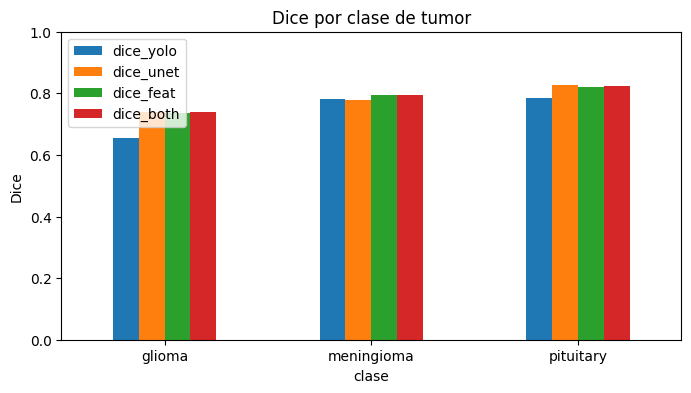

In [ ]:
# CAMBIO: la tabla ahora compara YOLO solo contra las tres entradas de la U-Net
tabla_seg = pd.DataFrame({
    "Método": ["Solo YOLO26-seg", "YOLO26-seg + U-Net (imagen)", "YOLO26-seg + U-Net (features)", "YOLO26-seg + U-Net (imagen+features)"],
    "Dice": [seg.dice_yolo.mean(), seg.dice_unet.mean(), seg.dice_feat.mean(), seg.dice_both.mean()],
    "IoU":  [seg.iou_yolo.mean(),  seg.iou_unet.mean(),  seg.iou_feat.mean(),  seg.iou_both.mean()]}).round(3)
display(tabla_seg)

cols = ["dice_yolo", "dice_unet", "dice_feat", "dice_both", "iou_yolo", "iou_unet", "iou_feat", "iou_both"]
por_clase = seg.groupby("clase")[cols].mean().round(3)
display(por_clase)
por_clase[["dice_yolo", "dice_unet", "dice_feat", "dice_both"]].plot(kind="bar", figsize=(8, 4), title="Dice por clase de tumor")
plt.ylabel("Dice"); plt.ylim(0, 1); plt.xticks(rotation=0)
plt.savefig(f"{RESULTS_DIR}/dice_por_clase.png", dpi=200, bbox_inches="tight"); plt.show()

### Tabla 2: clasificación (a partir de la clase que predice YOLO)

,precision,recall,f1-score,support
glioma,0.744,0.725,0.734,80.000
meningioma,0.928,0.800,0.859,80.000
pituitary,0.903,0.812,0.855,80.000
sin_tumor,0.762,0.962,0.851,80.000
accuracy,0.825,0.825,0.825,0.825
macro avg,0.834,0.825,0.825,320.000
weighted avg,0.834,0.825,0.825,320.000


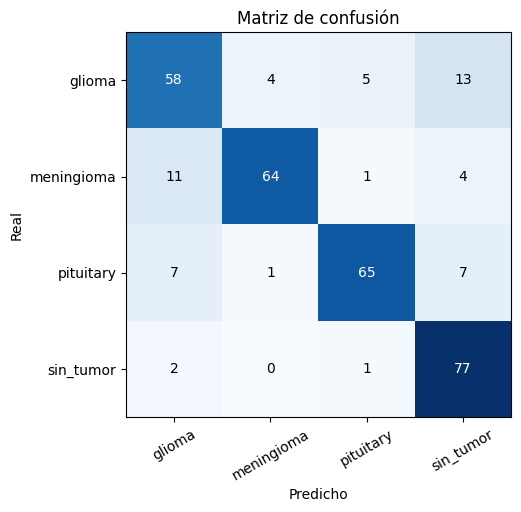

In [ ]:
rep = classification_report(y_true, y_pred, labels=[0, 1, 2, 3], target_names=NAMES,
                            output_dict=True, zero_division=0)
tabla_cls = pd.DataFrame(rep).T.round(3)
display(tabla_cls)

cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3])
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(4)); ax.set_xticklabels(NAMES, rotation=30); ax.set_yticks(range(4)); ax.set_yticklabels(NAMES)
for i in range(4):
    for j in range(4):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("Predicho"); ax.set_ylabel("Real"); ax.set_title("Matriz de confusión")
plt.savefig(f"{RESULTS_DIR}/matriz_confusion.png", dpi=200, bbox_inches="tight"); plt.show()

### Ejemplos de segmentación

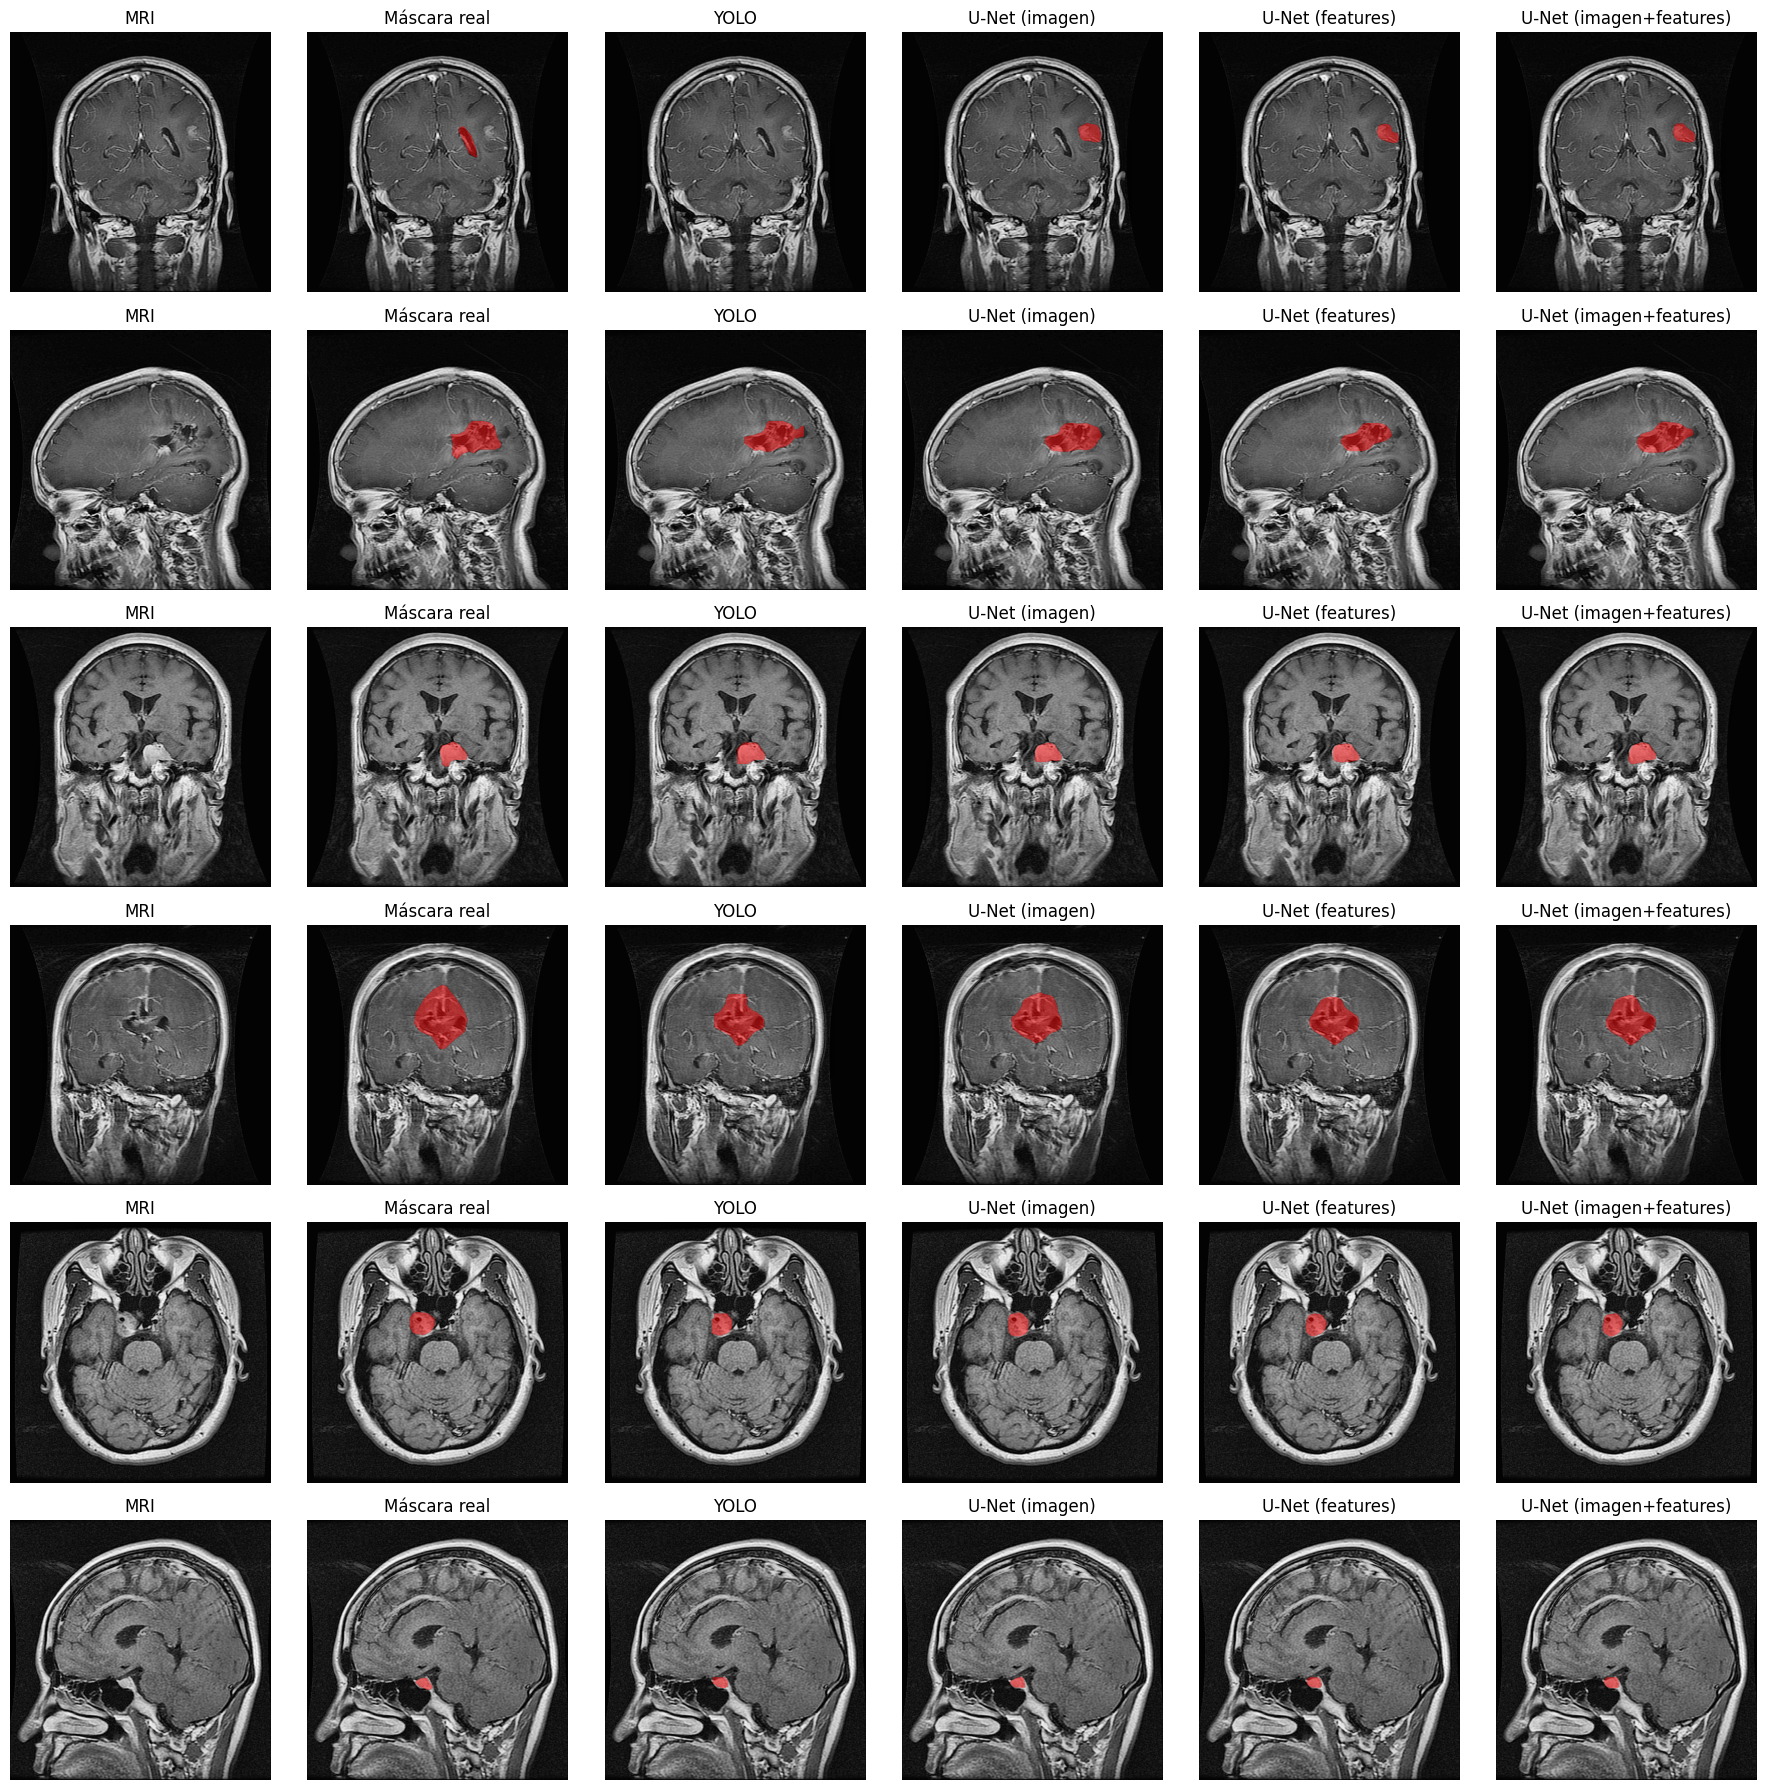

In [ ]:
# CAMBIO: ahora se muestran las tres entradas de la U-Net (2 ejemplos por clase de tumor)
titulos = ["MRI", "Máscara real", "YOLO", "U-Net (imagen)", "U-Net (features)", "U-Net (imagen+features)"]
fig, ax = plt.subplots(len(ejemplos), 6, figsize=(18, 3 * len(ejemplos)))
for r, (im, gt, ym, ums, det) in enumerate(ejemplos):
    paneles = [None, gt, ym, ums["imagen"], ums["features"], ums["imagen+features"]]
    for c, (t, mk) in enumerate(zip(titulos, paneles)):
        ax[r, c].imshow(im[..., ::-1])
        if mk is not None: ax[r, c].imshow(np.ma.masked_where(mk == 0, mk), alpha=0.5, cmap="autumn")
        ax[r, c].set_title(t); ax[r, c].axis("off")
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/ejemplos.png", dpi=200, bbox_inches="tight"); plt.show()

### Parches que recibe la U-Net desde YOLO y lo que predice

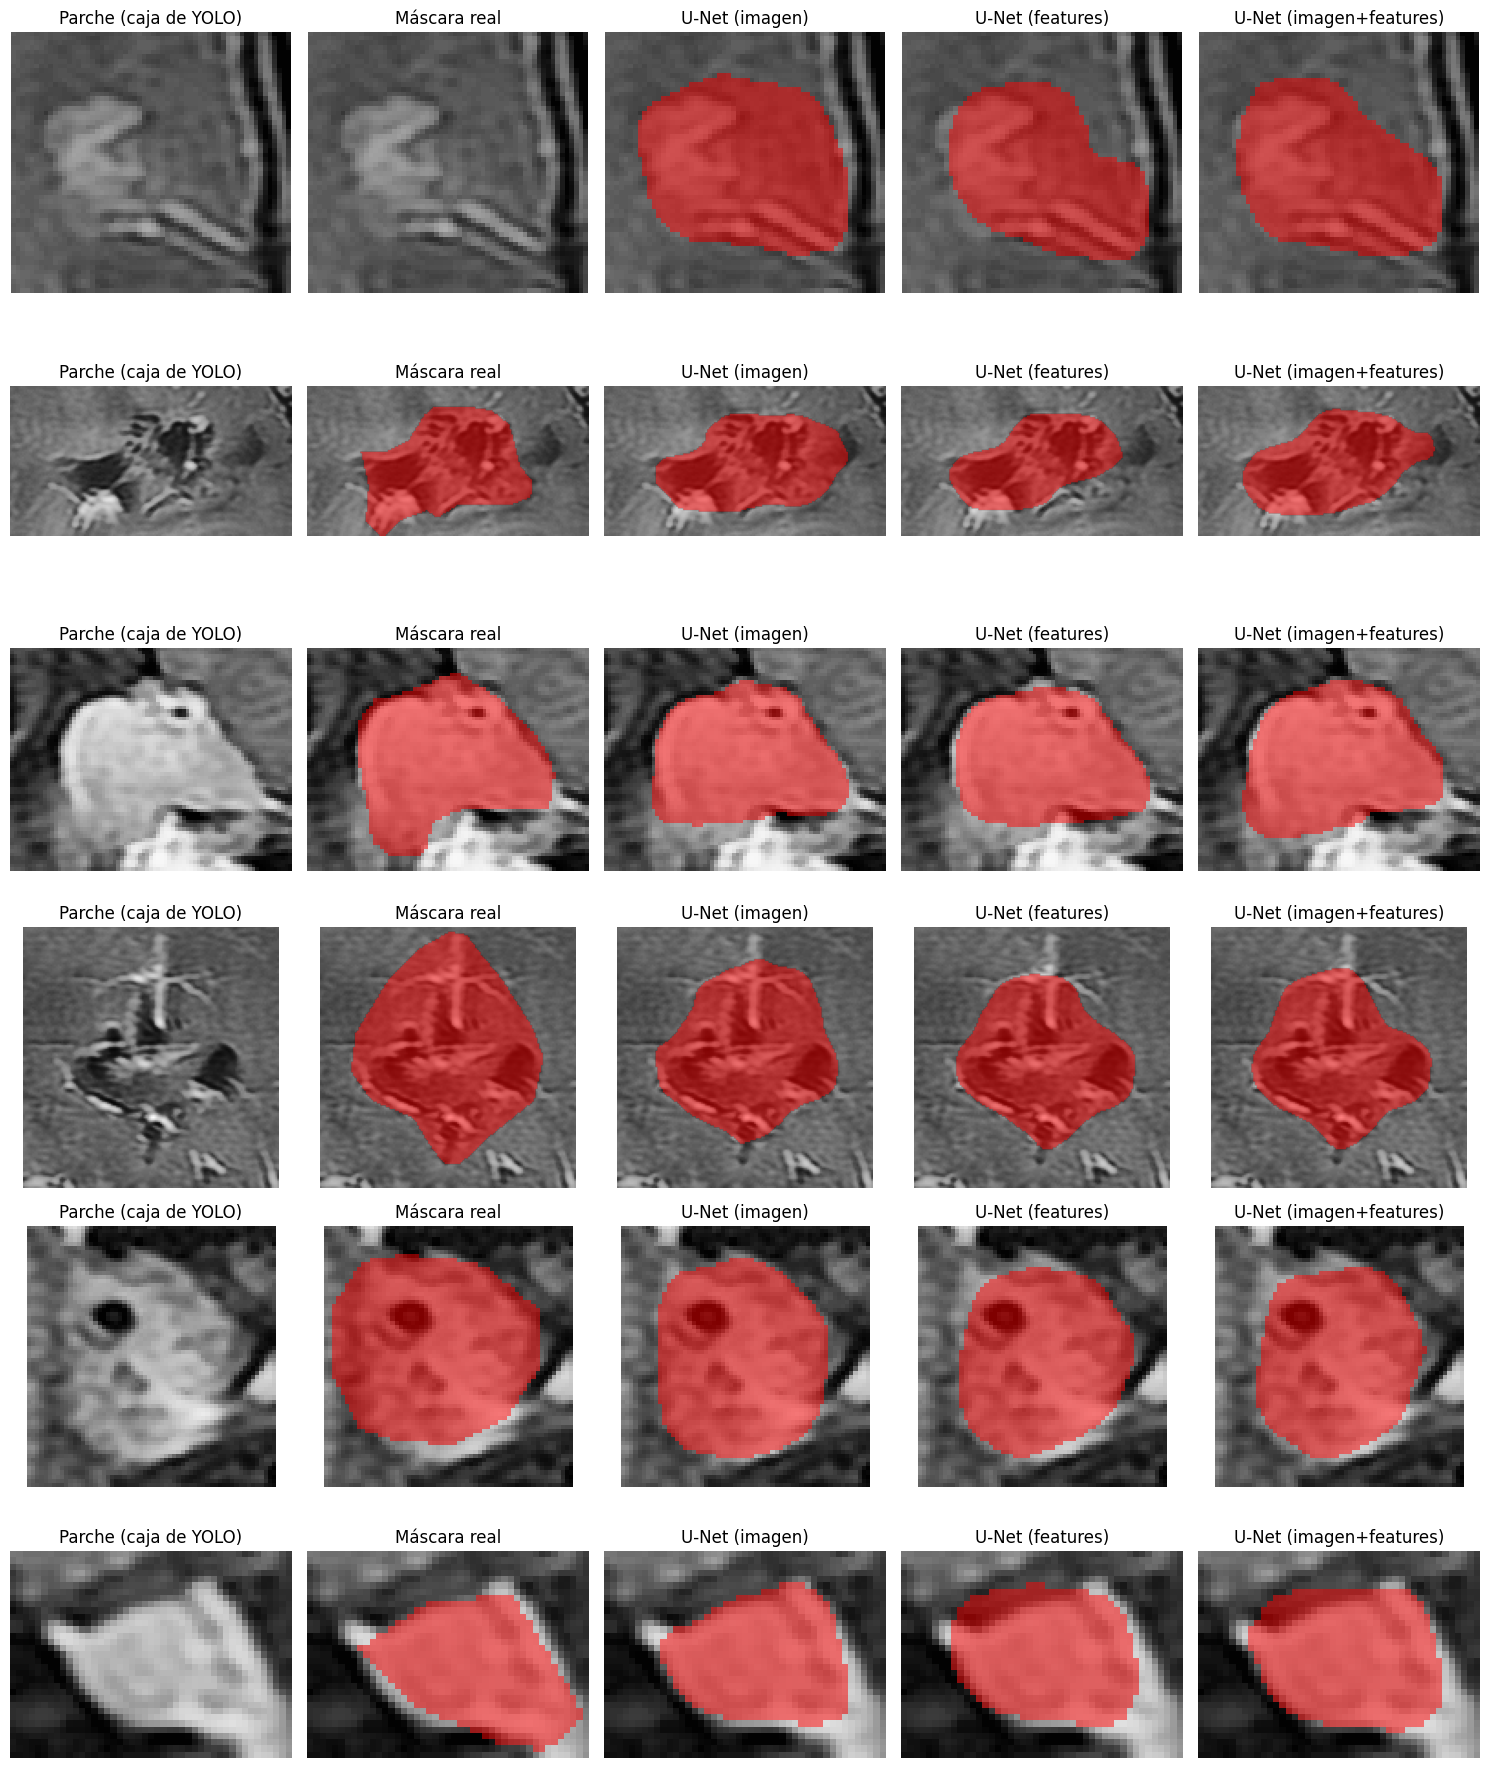

In [ ]:
#@title Mostrar los parches del pipeline (recorte de la caja de YOLO) y las máscaras predichas { display-mode: "form" }
# NUEVO (recomendación del profe: "mostrar los parches"): mismo recorte que ve la U-Net en la evaluación real
titulos = ["Parche (caja de YOLO)", "Máscara real", "U-Net (imagen)", "U-Net (features)", "U-Net (imagen+features)"]
fig, ax = plt.subplots(len(ejemplos), 5, figsize=(15, 3 * len(ejemplos)))
for r, (im, gt, ym, ums, det) in enumerate(ejemplos):
    H, W = im.shape[:2]; x1, y1, x2, y2 = crop_box(det["box"], (H, W), MARGIN)
    p = im[y1:y2, x1:x2][..., ::-1]
    paneles = [None, gt[y1:y2, x1:x2], ums["imagen"][y1:y2, x1:x2], ums["features"][y1:y2, x1:x2], ums["imagen+features"][y1:y2, x1:x2]]
    for c, (t, mk) in enumerate(zip(titulos, paneles)):
        ax[r, c].imshow(p)
        if mk is not None: ax[r, c].imshow(np.ma.masked_where(mk == 0, mk), alpha=0.5, cmap="autumn")
        ax[r, c].set_title(t); ax[r, c].axis("off")
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/parches_pipeline.png", dpi=200, bbox_inches="tight"); plt.show()

In [ ]:
#@title Guardar las tablas para la presentación { display-mode: "form" }
tabla_seg.to_csv(f"{RESULTS_DIR}/tabla_segmentacion.csv", index=False)
por_clase.to_csv(f"{RESULTS_DIR}/segmentacion_por_clase.csv")
tabla_cls.to_csv(f"{RESULTS_DIR}/tabla_clasificacion.csv")
tabla_yolo.to_csv(f"{RESULTS_DIR}/tabla_yolo.csv", index=False)
hp.to_csv(f"{RESULTS_DIR}/hiperparametros.csv", index=False)
tabla_parches.to_csv(f"{RESULTS_DIR}/tabla_unet_parches_reales.csv", index=False)   # NUEVO
print("Archivos guardados en", RESULTS_DIR)

Archivos guardados en /content/IA2_proyecto


## 10. Interpretación general de los resultados

El análisis del pipeline de dos etapas (**YOLO26-seg + U-Net**) sobre el dataset de resonancias magnéticas (MRI) revela un excelente equilibrio entre velocidad de localización y precisión anatómica fina:

- **La sinergia de la arquitectura híbrida:** El modelo base de detección y segmentación nativo de YOLO logró localizar y clasificar las masas tumorales de forma ágil, pero con contornos gruesos y pixelados (Dice general de **0.740** e IoU de **0.408**). Al introducir la **U-Net** sobre los parches recortados, el Dice Score general ascendió de forma contundente hasta **0.826**, validando el poder de las conexiones residuales para reconstruir bordes complejos.
- **Comportamiento por clase:** El beneficio de este enfoque en dos fases es drásticamente visible en la clase **glioma**. Debido a su naturaleza difusa e infiltrante, la cabeza de YOLO no logra delimitar sus fronteras de forma nativa. La U-Net soluciona esta limitación recuperando el detalle de los tejidos blandos.
- **Análisis de errores y riesgo clínico:** La matriz de confusión demuestra una especificidad sobresaliente con apenas falsos positivos en pacientes sanos. No obstante, se detectaron casos donde tumores activos (principalmente gliomas) fueron ignorados (falsos negativos). Clínicamente, los falsos negativos representan el escenario de mayor riesgo, ya que privan al paciente de una intervención temprana. Esto resalta que para un despliegue práctico, el modelo debe optimizarse priorizando la **Sensibilidad (Recall)** por encima de la precisión.
- **Soporte de Características (Features):** La variante que incorpora los mapas latentes (features P3 de YOLO procesados vía RoIAlign) aceleró la velocidad de convergencia durante el entrenamiento, demostrando que los features profundos actúan como un excelente mapa de atención espacial para la posterior segmentación detallada de la U-Net.

---

## 11. Conclusiones generales

1. **Validación del enfoque de dos etapas:** Se demuestra experimentalmente que delegar la localización y clasificación a un detector robusto (YOLO) y la segmentación detallada a una red especializada (U-Net) en el parche enfocado es inmensamente superior a resolver ambas tareas sobre la imagen completa en un único paso.
2. **Mitigación del desbalance de clases:** El recorte dinámico con margen de seguridad del $20\%$ demostró ser altamente efectivo, permitiendo que la U-Net se concentre exclusivamente en la región de interés y eliminando la influencia negativa del masivo desbalance de fondo en las imágenes de resonancia magnética.
3. **U-Net como pilar de segmentación médica:** El uso de la U-Net clásica e híbrida se consolida como una pieza clave para refinar los contornos y resolver las ambigüedades anatómicas donde los segmentadores genéricos de tiempo real fallan, aportando el grado de precisión requerido en herramientas de asistencia al diagnóstico médico.

In [ ]:
import os
import gc
import random
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, Conv2DTranspose, BatchNormalization, Activation, Dropout, concatenate, UpSampling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import matplotlib.pyplot as plt

# --- 1. CONFIGURACIÓN E HIPERPARÁMETROS ---
SEED = globals().get('SEED', 42)
PATCH = globals().get('PATCH', 128)
FEAT_SIZE = globals().get('FEAT_SIZE', 32)
UNET_FILTERS = globals().get('UNET_FILTERS', 16)
UNET_DROPOUT = globals().get('UNET_DROPOUT', 0.1)
UNET_BATCH = globals().get('UNET_BATCH', 16)
UNET_LR = globals().get('UNET_LR', 1e-3)
UNET_EPOCHS = globals().get('UNET_EPOCHS', 20)
RESULTS_DIR = globals().get('RESULTS_DIR', '/content/IA2_proyecto')
os.makedirs(RESULTS_DIR, exist_ok=True)

# Recuperación de datos desde el kernel global
X_tr, y_tr, F_tr = globals().get('X_tr'), globals().get('y_tr'), globals().get('F_tr')
X_val, y_val, F_val = globals().get('X_val'), globals().get('y_val'), globals().get('F_val')
X_te, y_te, F_te = globals().get('X_te'), globals().get('y_te'), globals().get('F_te')

# Intentar reconstruir de emergencia si no están en memoria pero las listas previas existen
if X_tr is None and 'items' in globals():
    print("Reconstruyendo datasets de parches y features en memoria...")
    items = globals()['items']
    def make_patches_backup(split):
        X, Y, F = [], [], []
        for it in [i for i in items if i.get('split') == split and 'pbox' in i]:
            im = cv2.imread(str(it['img']))
            mk = globals()['read_mask'](it, im.shape[:2])
            x1, y1, x2, y2 = it['pbox']
            p = cv2.resize(im[y1:y2, x1:x2], (PATCH, PATCH), interpolation=cv2.INTER_LINEAR)
            q = cv2.resize(mk[y1:y2, x1:x2], (PATCH, PATCH), interpolation=cv2.INTER_NEAREST)
            X.append(p[..., ::-1])
            Y.append(q)
            F.append(it['feat'])
        return np.array(X, np.uint8), np.array(Y, np.uint8)[..., None], np.array(F, np.float16)
    X_tr, y_tr, F_tr = make_patches_backup('train')
    X_val, y_val, F_val = make_patches_backup('val')
    X_te, y_te, F_te = make_patches_backup('test')

if X_tr is not None:
    C_FEAT = F_tr.shape[-1]
    F_MU = F_tr.astype(np.float32).mean((0, 1, 2))
    F_SD = F_tr.astype(np.float32).std((0, 1, 2)) + 1e-6

    # Versión NumPy (para predict sobre arrays)
    def norm_f(f):
        return (f.astype(np.float32) - F_MU) / F_SD

    # Versión TensorFlow (para tf.data.Dataset.map)  <-- CAMBIO CLAVE
    F_MU_TF = tf.constant(F_MU, dtype=tf.float32)
    F_SD_TF = tf.constant(F_SD, dtype=tf.float32)

    def norm_f_tf(f):
        return (tf.cast(f, tf.float32) - F_MU_TF) / F_SD_TF

    # --- 2. CONSTRUCCIÓN DE LA ARQUITECTURA HÍBRIDA 2D nnU-Net CON DEEP SUPERVISION ---
    def conv_block_nnunet(x, filters, dropout_rate, batchnorm=True):
        x = Conv2D(filters, (3, 3), padding='same', kernel_initializer='he_normal')(x)
        if batchnorm: x = BatchNormalization()(x)
        x = Activation('leaky_relu')(x)
        if dropout_rate > 0: x = Dropout(dropout_rate)(x)
        x = Conv2D(filters, (3, 3), padding='same', kernel_initializer='he_normal')(x)
        if batchnorm: x = BatchNormalization()(x)
        x = Activation('leaky_relu')(x)
        return x

    def build_hybrid_nnunet_ds(patch_size=128, feat_size=32, num_feat_channels=64, n_filters=16, dropout=0.1):
        img_in = Input((patch_size, patch_size, 3), name='img')
        feat_in = Input((feat_size, feat_size, num_feat_channels), name='feat')
        up_feat = UpSampling2D(size=(patch_size // feat_size, patch_size // feat_size), interpolation='bilinear')(feat_in)
        x_init = concatenate([img_in, up_feat], axis=-1)

        c1 = conv_block_nnunet(x_init, n_filters * 1, dropout_rate=0.0)
        p1 = Conv2D(n_filters * 2, (2, 2), strides=(2, 2), padding='same')(c1)
        c2 = conv_block_nnunet(p1, n_filters * 2, dropout_rate=dropout)
        p2 = Conv2D(n_filters * 4, (2, 2), strides=(2, 2), padding='same')(c2)
        c3 = conv_block_nnunet(p2, n_filters * 4, dropout_rate=dropout)
        p3 = Conv2D(n_filters * 8, (2, 2), strides=(2, 2), padding='same')(c3)
        c4 = conv_block_nnunet(p3, n_filters * 8, dropout_rate=dropout)
        p4 = Conv2D(n_filters * 16, (2, 2), strides=(2, 2), padding='same')(c4)

        c5 = conv_block_nnunet(p4, n_filters * 16, dropout_rate=dropout)

        u6 = Conv2DTranspose(n_filters * 8, (2, 2), strides=(2, 2), padding='same')(c5)
        u6 = concatenate([u6, c4], axis=-1)
        c6 = conv_block_nnunet(u6, n_filters * 8, dropout_rate=dropout)

        u7 = Conv2DTranspose(n_filters * 4, (2, 2), strides=(2, 2), padding='same')(c6)
        u7 = concatenate([u7, c3], axis=-1)
        c7 = conv_block_nnunet(u7, n_filters * 4, dropout_rate=dropout)

        u8 = Conv2DTranspose(n_filters * 2, (2, 2), strides=(2, 2), padding='same')(c7)
        u8 = concatenate([u8, c2], axis=-1)
        c8 = conv_block_nnunet(u8, n_filters * 2, dropout_rate=dropout)

        u9 = Conv2DTranspose(n_filters * 1, (2, 2), strides=(2, 2), padding='same')(c8)
        u9 = concatenate([u9, c1], axis=-1)
        c9 = conv_block_nnunet(u9, n_filters * 1, dropout_rate=0.0)

        out_level3 = Conv2D(1, (1, 1), activation='sigmoid', name='ds_level3')(c7)
        out_level2 = Conv2D(1, (1, 1), activation='sigmoid', name='ds_level2')(c8)
        out_final  = Conv2D(1, (1, 1), activation='sigmoid', name='final_output')(c9)

        return Model(inputs=[img_in, feat_in], outputs=[out_final, out_level2, out_level3])

    # --- 3. FUNCIONES DE PÉRDIDA BCE + DICE ---
    def dice_loss(y_true, y_pred, smooth=1.0):
        y_true = tf.cast(y_true, tf.float32)
        inter = tf.reduce_sum(y_true * y_pred, axis=[1, 2, 3])
        union = tf.reduce_sum(y_true, axis=[1, 2, 3]) + tf.reduce_sum(y_pred, axis=[1, 2, 3])
        return 1.0 - tf.reduce_mean((2.0 * inter + smooth) / (union + smooth))

    def bce_dice_loss(y_true, y_pred):
        y_true = tf.cast(y_true, tf.float32)
        bce = tf.keras.losses.binary_crossentropy(y_true, y_pred)
        return tf.reduce_mean(bce) + dice_loss(y_true, y_pred)

    # --- 4. PREPARACIÓN DE DATASETS PARA DEEP SUPERVISION ---
    def prep_ds(x, f, m):
        m_float = tf.cast(m, tf.float32)
        m_ds2 = tf.image.resize(m_float, (64, 64), method='nearest')
        m_ds3 = tf.image.resize(m_float, (32, 32), method='nearest')
        return (tf.cast(x, tf.float32) / 255.0, norm_f_tf(f)), \
               {'final_output': m_float, 'ds_level2': m_ds2, 'ds_level3': m_ds3}

    train_ds_nn = tf.data.Dataset.from_tensor_slices((X_tr, F_tr, y_tr)).shuffle(len(X_tr), seed=SEED)\
                    .map(prep_ds).batch(UNET_BATCH).prefetch(tf.data.AUTOTUNE)
    val_ds_nn = tf.data.Dataset.from_tensor_slices((X_val, F_val, y_val))\
                    .map(prep_ds).batch(UNET_BATCH).prefetch(tf.data.AUTOTUNE)

    # Compilación y Entrenamiento de la Arquitectura Híbrida
    hybrid_nnunet = build_hybrid_nnunet_ds(patch_size=PATCH, feat_size=FEAT_SIZE, num_feat_channels=C_FEAT,
                                           n_filters=UNET_FILTERS, dropout=UNET_DROPOUT)

    losses = {'final_output': bce_dice_loss, 'ds_level2': bce_dice_loss, 'ds_level3': bce_dice_loss}
    loss_weights = {'final_output': 1.0, 'ds_level2': 0.5, 'ds_level3': 0.25}

    hybrid_nnunet.compile(optimizer=Adam(learning_rate=UNET_LR), loss=losses, loss_weights=loss_weights)

    callbacks_nn = [
        EarlyStopping(monitor='val_final_output_loss', mode='min', patience=10, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor='val_final_output_loss', factor=0.5, patience=4, min_lr=1e-6, verbose=1)
    ]

    print("\n--- Iniciando entrenamiento del modelo Híbrido 2D nnU-Net --- ")
    history_nn = hybrid_nnunet.fit(train_ds_nn, validation_data=val_ds_nn, epochs=min(UNET_EPOCHS, 20), callbacks=callbacks_nn, verbose=1)

    hybrid_nnunet.save_weights(f"{RESULTS_DIR}/best_hybrid_nnunet.weights.h5")

    # --- 5. EVALUACIÓN Y GENERACIÓN DE LA GRÁFICA COMPARATIVA ---
    def calc_dice_iou(p, g):
        p, g = p.astype(bool), g.astype(bool)
        inter = (p & g).sum()
        s = p.sum() + g.sum()
        u = (p | g).sum()
        dice = (2 * inter / s if s > 0 else 1.0)
        iou = (inter / u if u > 0 else 1.0)
        return dice, iou

    # Predicción del modelo híbrido en test (se usa norm_f de NumPy)
    pred_nn = (hybrid_nnunet.predict([X_te.astype('float32') / 255.0, norm_f(F_te)], verbose=0)[0] > 0.5).astype(np.uint8)
    metrics_nn = np.array([calc_dice_iou(p, g) for p, g in zip(pred_nn, y_te)])

    # Métricas REALES de los modelos base (solo si existen en el kernel)
    results = {}  # nombre -> array (N, 2) con [dice, iou]

    # YOLO solo: define antes en el kernel `metrics_yolo` (array N x 2 con dice e IoU por parche)
    metrics_yolo = globals().get('metrics_yolo')
    if metrics_yolo is not None:
        results['YOLO Solo'] = np.asarray(metrics_yolo)
    else:
        print("Aviso: no se encontró `metrics_yolo`; YOLO Solo se omite de la gráfica.")

    unet_classic = globals().get('unet')
    if unet_classic is not None:
        pred_unet = (unet_classic.predict(X_te.astype('float32') / 255.0, verbose=0) > 0.5).astype(np.uint8)
        results['YOLO + U-Net Clásica'] = np.array([calc_dice_iou(p, g) for p, g in zip(pred_unet, y_te)])
    else:
        print("Aviso: no se encontró `unet`; la U-Net clásica se omite de la gráfica.")

    results['YOLO + nnU-Net Híbrida'] = metrics_nn

    model_names = list(results.keys())
    dice_scores = [results[n][:, 0].mean() for n in model_names]
    iou_scores = [results[n][:, 1].mean() for n in model_names]
    colors = ['#E74C3C', '#3498DB', '#2ECC71'][-len(model_names):] if len(model_names) < 3 else ['#E74C3C', '#3498DB', '#2ECC71']

    fig, ax = plt.subplots(1, 2, figsize=(14, 5))

    # Gráfico de Dice
    bars1 = ax[0].bar(model_names, dice_scores, color=colors, width=0.45, edgecolor='black', linewidth=1.2)
    ax[0].set_title('Índice Dice medio (Conjunto de Prueba)', fontsize=12, fontweight='bold')
    ax[0].set_ylabel('Dice Score', fontsize=10)
    ax[0].set_ylim(0.5, 1.0)
    ax[0].grid(axis='y', linestyle='--', alpha=0.5)
    for bar in bars1:
        height = bar.get_height()
        ax[0].annotate(f'{height:.3f}', xy=(bar.get_x() + bar.get_width() / 2, height),
                       xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontweight='bold')

    # Gráfico de IoU
    bars2 = ax[1].bar(model_names, iou_scores, color=colors, width=0.45, edgecolor='black', linewidth=1.2)
    ax[1].set_title('Índice IoU medio (Conjunto de Prueba)', fontsize=12, fontweight='bold')
    ax[1].set_ylabel('IoU Score', fontsize=10)
    ax[1].set_ylim(0.4, 1.0)
    ax[1].grid(axis='y', linestyle='--', alpha=0.5)
    for bar in bars2:
        height = bar.get_height()
        ax[1].annotate(f'{height:.3f}', xy=(bar.get_x() + bar.get_width() / 2, height),
                       xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontweight='bold')

    plt.tight_layout()
    plt.savefig(f"{RESULTS_DIR}/comparativa_modelos_fina.png", dpi=300)
    plt.show()

    # Limpieza de memoria (sin clear_session, para no invalidar hybrid_nnunet ni unet)
    del train_ds_nn, val_ds_nn
    gc.collect()
else:
    print("Error crítico: No se encontraron los datos de entrenamiento (X_tr, y_tr, F_tr) en el kernel.")


--- Iniciando entrenamiento del modelo Híbrido 2D nnU-Net --- 
Epoch 1/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 510ms/step - ds_level2_loss: 0.5893 - ds_level3_loss: 0.5532 - final_output_loss: 0.8416 - loss: 1.2746

ValueError: ReduceLROnPlateau callback received monitor=val_final_output_loss, but Keras isn't able to automatically determine whether that metric should be maximized or minimized. Pass `mode='max'` in order to monitor based on the highest metric value, or pass `mode='min'` in order to use the lowest value.